# Caso 6.2 · Clasificación — Diagnóstico citológico: ¿tumor maligno o benigno?

**Libro:** *Metodología de Investigación Algocrática* · Capítulo 6 (Casos prácticos)
**Dataset:** Breast Cancer Wisconsin (Diagnostic), WDBC · **Plataforma:** Google Colab (también corre en local)

> ⚠️ **Aviso.** Este cuaderno es un **ejercicio metodológico**. No es una herramienta diagnóstica ni sustituye el criterio clínico. Los datos son un conjunto histórico y pequeño, y el valor del caso está en el **proceso de validación y auditoría**, no en el modelo.

---

## Cómo usar este cuaderno

1. Ejecuta de arriba hacia abajo (*Entorno de ejecución → Ejecutar todo*). **No hay que descargar nada**: el dataset viene incluido en scikit-learn. (Si prefieres usar tu propio CSV, indica la ruta en `ARCHIVO_CSV` de la Celda 2.)
2. **Cada celda de código está precedida por una celda de texto (🔎)** que explica *qué hace*, *por qué* y *qué observar en la salida*.
3. Al final se generan los **artefactos auditables** (reporte técnico, manifiesto, pre-registro, figuras, modelo) en `caso62_salidas/`, comprimidos en un `.zip`.

## Mapa del cuaderno (Modelo de 6 pasos del Capítulo 2)

| Paso | Qué se hace | Celdas |
|---|---|---|
| — | Planteamiento y tipo de problema | (texto) |
| — | Entorno, semillas y registro de auditoría | 1 |
| **1** | Identificar el dataset y perfilarlo | 2 – 3 |
| **2** | Objetivo, métrica, umbral de decisión y criterios **pre-registrados** | 4 |
| **3** | Preparar los datos: partición estratificada, *test sellado*, estructura | 5 – 7 |
| **4** | Elegir familias de modelos y justificarlas | 8 |
| **5** | Entrenar y validar: CV repetida, curvas, CV anidada, umbral, calibración | 9 – 12 |
| **6** | Evaluación final, errores, interpretabilidad, documentación y auditoría | 13 – 17 |
| Extra | Trampa deliberada: fuga por selección de variables (opcional) | 18 |

## Convenciones

- Los parámetros editables están en la **Celda 1**. `MODO_RAPIDO = True` es una *prueba de humo*; **sus resultados no son válidos para el libro**.
- Tiempo estimado con `MODO_RAPIDO = False`: unos **3 a 8 minutos** en CPU de Colab (mi prueba completa tardó 2 minutos en una sola CPU).
- Todo número que aparece en el reporte final proviene de la ejecución; nada está escrito a mano.
- **Clase positiva = maligno.** Más abajo se explica por qué esta convención importa.

# 1. Planteamiento del problema

## Contexto

La **punción-aspiración con aguja fina (PAAF)** extrae células de una masa mamaria para examinarlas. En el dataset WDBC, a partir de una **imagen digitalizada** de la muestra se calculan, para los núcleos celulares, diez medidas de tamaño, forma y textura. De cada medida se registran tres estadísticos por imagen: la **media**, el **error estándar** y el valor **más extremo** ("worst", la media de los tres mayores): 10 × 3 = **30 variables numéricas**.

El conjunto reúne **569 casos** (**212 malignos** y **357 benignos**) y es una copia del repositorio UCI (Street, Wolberg y Mangasarian, 1993).

| Medida (por núcleo) | Qué describe |
|---|---|
| `radius` | Media de distancias del centro al borde |
| `texture` | Desviación estándar de los niveles de gris |
| `perimeter`, `area` | Tamaño |
| `smoothness` | Variación local de los radios |
| `compactness` | perímetro² / área − 1 |
| `concavity`, `concave points` | Severidad y número de porciones cóncavas del contorno |
| `symmetry`, `fractal dimension` | Simetría y aproximación de "costa" − 1 |

## Pregunta de investigación

> ¿Es posible discriminar entre tumores malignos y benignos a partir de las 30 medidas nucleares, con una **sensibilidad** y una **especificidad** aceptables, y con una incertidumbre **cuantificada y auditable**? ¿La complejidad adicional de un modelo no lineal se justifica frente a un modelo simple?

## Objetivos

1. **O1.** Construir un clasificador probabilístico de la clase "maligno".
2. **O2.** Elegir un **umbral de decisión** según el costo asimétrico de los errores, sin usar el test.
3. **O3.** Cuantificar la incertidumbre (intervalos para sensibilidad, especificidad, AUC) y auditar la **calibración**.
4. **O4.** Decidir si la complejidad se justifica (regla de **parsimonia** pre-registrada).
5. **O5.** Documentar un artefacto reproducible y declarar sus límites.

## Hipótesis de rendimiento (la forma algocrática de H₀/H₁)

- **H₀:** el modelo seleccionado **no** cumple simultáneamente los cuatro criterios pre-registrados (Celda 4).
- **H₁:** el modelo seleccionado cumple **sensibilidad, especificidad, calibración y estabilidad** declaradas de antemano.

## Alcance y límites (declarados desde el inicio)

- **Dataset pequeño** (569 casos). Con ≈ 114 casos de prueba y ≈ 42 malignos, los intervalos de confianza serán **anchos**: cualquier cifra puntual debe leerse junto con su intervalo.
- **Sin identificador de paciente:** no se puede verificar que las filas sean independientes (varias muestras de una misma paciente producirían fuga). Se declara como supuesto.
- **Sin variables demográficas:** no se pueden auditar sesgos entre subgrupos (el pilar de sesgo del libro queda **sin cubrir por limitación de los datos**).
- **Las variables dependen de un proceso de medición** (segmentación de imágenes): el modelo hereda su validez y sus errores.
- **La prevalencia del dataset (37 % malignos) no es la de un programa de tamizaje**; los valores predictivos dependen de la prevalencia y no son transferibles (se ilustra en la Celda 14).
- **Uso no clínico.**

## Por qué importa

Es un caso donde un número alto de exactitud puede **ocultar** lo importante: qué tipo de error se comete, con qué incertidumbre y bajo qué costos. Es el escenario ideal para mostrar por qué el rigor algocrático exige **más** que reportar un "97 %".

# 2. ¿Por qué es un problema de **clasificación** y no de regresión ni de clustering?

## Preguntas guía

| # | Pregunta | Respuesta en este caso | Consecuencia |
|---|---|---|---|
| 1 | ¿Existe una variable objetivo **medida**? | Sí: el diagnóstico (maligno/benigno) confirmado | Aprendizaje **supervisado** (el clustering no es el análisis principal) |
| 2 | ¿Qué naturaleza tiene? | **Categórica** de dos clases | **Clasificación binaria** (no regresión) |
| 3 | ¿Qué se quiere decidir? | A qué clase pertenece cada caso | Se necesita una **regla de decisión** (umbral) sobre una probabilidad |
| 4 | ¿Los errores cuestan lo mismo? | **No**: dejar pasar un maligno (falso negativo) es más grave que un falso positivo | Métricas y umbral deben reflejar **costos asimétricos** |

## Por qué no regresión

El objetivo es una **etiqueta**, no una magnitud. Aunque el modelo produzca una *probabilidad* (un número entre 0 y 1), ese número no es el objetivo observado: es una **estimación de la probabilidad de la clase**. Tratar "0/1" como una cantidad y ajustar una regresión lineal produciría valores fuera de [0, 1] y errores sin interpretación clínica.

## Por qué no clustering

El clustering **no usa etiquetas**: busca grupos en las variables. Aquí **tenemos** las etiquetas y la pregunta es justamente predecirlas. El clustering puede servir como **exploración complementaria**: la Celda 7 comprueba *empíricamente* hasta qué punto dos clusters sin etiquetas coinciden con el diagnóstico. Si no coinciden del todo, usar las etiquetas (clasificación) aporta información que el clustering no puede recuperar.

## Una trampa de codificación

scikit-learn codifica este dataset como **0 = maligno, 1 = benigno**, lo contrario de la convención clínica en que la clase de interés (maligno) es la **positiva**. Si no se recodifica, la "sensibilidad" calculada por defecto sería la capacidad de detectar **benignos**. En la Celda 2 se recodifica explícitamente a **1 = maligno** y se verifica con los conteos documentados.

## Traducción al lenguaje algocrático

| Término tradicional | Término algocrático en este caso |
|---|---|
| Variable dependiente (diagnóstico) | Objetivo (*target*) `maligno` ∈ {0, 1} |
| Variables independientes | 30 características nucleares |
| Validez de criterio | Sensibilidad, especificidad y AUC en el test sellado |
| Punto de corte clínico | Umbral de decisión pre-registrado, fijado **sin** el test |

## Consecuencias prácticas de que sea clasificación

- Métricas: **sensibilidad, especificidad, AUC, PR-AUC, Brier, calibración** (no RMSE).
- Partición **estratificada** (se conserva la proporción de clases en entrenamiento, validación y prueba).
- Auditoría de **errores por tipo** (FN y FP) y de la **calibración** de las probabilidades.

### 🔎 Celda 1 — Configuración, semillas y registro de auditoría

**Qué hace.** Importa librerías, fija las **semillas**, define los **parámetros editables**, crea la carpeta de salidas, inicializa el **manifiesto de ejecución** (versiones y plataforma) y un **registro de auditoría** (`log`) donde cada paso deja una huella con fecha UTC.

**Por qué.** La reproducibilidad se diseña desde la primera celda. Sin semilla, sin versiones y sin registro, nadie puede reproducir ni auditar el resultado.

**Qué observar.** Versiones, semilla y modo. Si ves el aviso de `MODO_RAPIDO`, los resultados son solo una prueba de funcionamiento.

In [ ]:
# CELDA 1 · Configuración, semillas y registro de auditoría
import os, sys, re, json, hashlib, platform, subprocess, time, warnings, zipfile, random
from datetime import datetime, timezone
from pathlib import Path

import numpy as np
import pandas as pd
import scipy
from scipy import stats
import sklearn
import matplotlib
import matplotlib.pyplot as plt

try:
    from IPython.display import display, Markdown
except Exception:                       # entorno sin IPython (p. ej., pruebas locales)
    def display(*args, **kwargs):
        for a in args:
            print(a)
    def Markdown(texto):
        return texto

warnings.filterwarnings("ignore", category=FutureWarning)

# ---------- Parámetros del estudio (editables) ----------
MODO_RAPIDO = False      # True = prueba de humo (menos repeticiones). NO usar para resultados del libro.
RANDOM_STATE = 42
TEST_SIZE = 0.20         # fracción reservada para el test sellado (estratificada)
N_SPLITS = 5             # folds de la validación cruzada
if MODO_RAPIDO:
    N_REPEATS, N_BOOT, N_ITER_BUSQUEDA, N_ITER_ANIDADA = 1, 300, 4, 3
    N_TREES, PERM_REPEATS, B_COEF, TRAMPA_R = 60, 5, 30, 6
else:
    N_REPEATS, N_BOOT, N_ITER_BUSQUEDA, N_ITER_ANIDADA = 3, 2000, 12, 8
    N_TREES, PERM_REPEATS, B_COEF, TRAMPA_R = 200, 30, 200, 20
EJECUTAR_TRAMPA = True   # Celda 18 (opcional)

# ---------- Semillas ----------
np.random.seed(RANDOM_STATE)
random.seed(RANDOM_STATE)
os.environ["PYTHONHASHSEED"] = str(RANDOM_STATE)
RNG = np.random.default_rng(RANDOM_STATE)

# ---------- Entorno y salidas ----------
EN_COLAB = "google.colab" in sys.modules
DIR_SALIDA = Path("/content/caso62_salidas") if EN_COLAB else Path("caso62_salidas")
DIR_SALIDA.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25,
                     "axes.spines.top": False, "axes.spines.right": False, "font.size": 10})

def guardar_fig(nombre, ajustar=True):
    """Guarda la figura actual en la carpeta de salidas y la muestra."""
    if ajustar:
        plt.tight_layout()
    ruta = DIR_SALIDA / nombre
    plt.savefig(ruta, dpi=200, bbox_inches="tight")
    plt.show()
    return ruta

# ---------- Registro de auditoría y manifiesto ----------
LOG_AUDITORIA = []
def log(evento, **datos):
    LOG_AUDITORIA.append({"t_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
                          "evento": evento, **datos})

def a_json(o):
    """Convierte tipos de NumPy/Path/fecha para poder guardarlos en JSON."""
    if isinstance(o, (np.integer,)):  return int(o)
    if isinstance(o, (np.floating,)): return float(o)
    if isinstance(o, (np.bool_,)):    return bool(o)
    if isinstance(o, np.ndarray):     return o.tolist()
    if isinstance(o, Path):           return str(o)
    if isinstance(o, datetime):       return o.isoformat()
    return str(o)

RESULTADOS = {}
MANIFIESTO = {
    "inicio_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
    "python": sys.version.split()[0],
    "plataforma": platform.platform(),
    "en_colab": EN_COLAB,
    "librerias": {"numpy": np.__version__, "pandas": pd.__version__, "scipy": scipy.__version__,
                  "scikit-learn": sklearn.__version__, "matplotlib": matplotlib.__version__},
    "semilla": RANDOM_STATE,
    "modo_rapido": MODO_RAPIDO,
    "parametros": {"test_size": TEST_SIZE, "n_splits": N_SPLITS, "n_repeats": N_REPEATS, "n_boot": N_BOOT,
                   "n_iter_busqueda": N_ITER_BUSQUEDA, "n_iter_anidada": N_ITER_ANIDADA},
}
log("inicio", semilla=RANDOM_STATE, modo_rapido=MODO_RAPIDO)

print("Python", MANIFIESTO["python"], "|", MANIFIESTO["plataforma"])
for k, v in MANIFIESTO["librerias"].items():
    print(f"  {k:13s} {v}")
print("Semilla:", RANDOM_STATE, "| Carpeta de salidas:", DIR_SALIDA.resolve())
if MODO_RAPIDO:
    print("\n⚠️  MODO_RAPIDO activo: resultados NO válidos para el libro (solo prueba de funcionamiento).")

Python 3.13.16 | Linux-6.6.122+-x86_64-with-glibc2.39
  numpy         2.1.3
  pandas        2.2.3
  scipy         1.16.3
  scikit-learn  1.6.1
  matplotlib    3.10.0
Semilla: 42 | Carpeta de salidas: /content/caso62_salidas


# Paso 1 · Identificar el dataset y perfilarlo

**Objetivo del paso.** Cargar los datos, **documentar su origen**, fijar la codificación del objetivo y registrar una fotografía inicial de su calidad *sin transformarlos*.
**Entregable clave.** Un **Perfil de datos** (tabla + figuras).
**Referencia normativa (marco de lectura).** Medidas de calidad de datos para analítica y ML (familia ISO/IEC 5259) y consideraciones de sesgo (IEEE 7003-2024). *Verifica las cláusulas exactas en las normas antes de citarlas.*

### 🔎 Celda 2 — Cargar el dataset y **fijar la codificación del objetivo**

**Qué hace.** Carga el dataset desde scikit-learn (copia del WDBC de UCI) o, si indicas `ARCHIVO_CSV`, desde un CSV con columna `diagnosis` (M/B) y las 30 columnas `*_mean`, `*_se`, `*_worst`. **Recodifica el objetivo a `maligno` (1 = maligno, 0 = benigno)** y construye un diccionario que agrupa las 30 variables por **medida base** (radio, textura, etc.). Compara los conteos con los **documentados** y calcula la **huella SHA-256** del contenido.

**Por qué.** La recodificación evita el error de codificación descrito en el planteamiento. La comparación con los conteos documentados (569, 212 malignos, 357 benignos) es una **verificación de integridad**. Los grupos por medida base se usarán para auditar la interpretabilidad (Celda 15), porque las tres versiones de una medida (media, error, peor valor) están muy correlacionadas.

**Qué observar.** Que los conteos coincidan con la documentación y que el ejemplo de la codificación muestre `maligno = 1`.

In [ ]:
# CELDA 2 · Cargar el dataset y fijar la codificación del objetivo (Paso 1)
ARCHIVO_CSV = None   # opcional: ruta a un CSV (columna 'diagnosis' M/B y columnas *_mean, *_se, *_worst)

BASES = ["radius", "texture", "perimeter", "area", "smoothness", "compactness", "concavity",
         "concave points", "symmetry", "fractal dimension"]
def nombre_sk(base, estadistico):
    return {"mean": f"mean {base}", "error": f"{base} error", "worst": f"worst {base}"}[estadistico]
COLUMNAS = [nombre_sk(b, s) for s in ("mean", "error", "worst") for b in BASES]
GRUPOS_BASE = {b: [nombre_sk(b, s) for s in ("mean", "error", "worst")] for b in BASES}
OBJETIVO = "maligno"

if ARCHIVO_CSV is None:
    from sklearn.datasets import load_breast_cancer
    bunch = load_breast_cancer(as_frame=True)
    X_df = bunch.data[COLUMNAS].copy()                     # verifica y ordena los nombres
    y_ser = (bunch.target == 0).astype(int)                # sklearn: 0 = maligno -> aquí 1 = maligno
    ORIGEN = {"fuente": "scikit-learn load_breast_cancer (copia del WDBC de UCI)",
              "clases_sklearn": list(bunch.target_names), "codificacion_sklearn": "0 = maligno, 1 = benigno"}
    ejemplo_cod = pd.DataFrame({"target sklearn": bunch.target.head(5).to_numpy(),
                                "clase (sklearn)": [bunch.target_names[i] for i in bunch.target.head(5)],
                                "maligno (aquí)": y_ser.head(5).to_numpy()})
else:
    crudo = pd.read_csv(ARCHIVO_CSV)
    ren = {}
    for c in crudo.columns:
        k = str(c).strip()
        for suf, est in (("_mean", "mean"), ("_se", "error"), ("_worst", "worst")):
            if k.endswith(suf):
                ren[c] = nombre_sk(k[:-len(suf)].replace("_", " "), est)
    X_df = crudo.rename(columns=ren)
    faltan = [c for c in COLUMNAS if c not in X_df.columns]
    if faltan or "diagnosis" not in crudo.columns:
        raise ValueError(f"El CSV no tiene el formato esperado. Faltan: {faltan[:5]} ... / columna 'diagnosis': {'diagnosis' in crudo.columns}")
    y_ser = crudo["diagnosis"].astype(str).str.strip().str.upper().map({"M": 1, "B": 0})
    if y_ser.isna().any():
        raise ValueError("La columna 'diagnosis' debe contener solo M o B.")
    X_df = X_df[COLUMNAS].apply(pd.to_numeric, errors="coerce")
    ORIGEN = {"fuente": f"CSV: {Path(ARCHIVO_CSV).name}", "codificacion_origen": "M/B"}
    ejemplo_cod = pd.DataFrame({"diagnosis (origen)": crudo["diagnosis"].head(5).to_numpy(),
                                "maligno (aquí)": y_ser.head(5).to_numpy()})

df = X_df.copy()
df[OBJETIVO] = y_ser.to_numpy()
df = df.reset_index(drop=True)

if ARCHIVO_CSV is None:
    HUELLA_DATOS = hashlib.sha256(pd.util.hash_pandas_object(df, index=False).to_numpy().tobytes()).hexdigest()
else:
    h = hashlib.sha256()
    with open(ARCHIVO_CSV, "rb") as f:
        for bloque in iter(lambda: f.read(1 << 20), b""):
            h.update(bloque)
    HUELLA_DATOS = h.hexdigest()

n, n_mal, n_ben = len(df), int(df[OBJETIVO].sum()), int((df[OBJETIVO] == 0).sum())
DOC = {"n": 569, "malignos": 212, "benignos": 357}
coincide = (n, n_mal, n_ben) == (DOC["n"], DOC["malignos"], DOC["benignos"])
print("Fuente:", ORIGEN["fuente"])
print(f"Casos: {n} | malignos: {n_mal} | benignos: {n_ben} | prevalencia de malignos: {n_mal / n:.1%}")
print("Coincide con lo documentado (569 / 212 / 357):", "SÍ ✔" if coincide else "NO ✘ — revisa el origen de los datos")
print("Huella SHA-256 del contenido:", HUELLA_DATOS)
print("\nCodificación del objetivo (primeras filas):")
display(ejemplo_cod)

MANIFIESTO["datos_origen"] = {**ORIGEN, "sha256": HUELLA_DATOS, "n_filas": n, "malignos": n_mal, "benignos": n_ben,
                              "coincide_con_documentacion": bool(coincide)}
log("carga_dataset", fuente=ORIGEN["fuente"], sha256=HUELLA_DATOS, coincide=bool(coincide))

Fuente: scikit-learn load_breast_cancer (copia del WDBC de UCI)
Casos: 569 | malignos: 212 | benignos: 357 | prevalencia de malignos: 37.3%
Coincide con lo documentado (569 / 212 / 357): SÍ ✔
Huella SHA-256 del contenido: 698f9064cb3927973dd96ee9f3950e3103f64ff87b0e84898a09b567e792fd02

Codificación del objetivo (primeras filas):


,target sklearn,clase (sklearn),maligno (aquí)
0,0,malignant,1
1,0,malignant,1
2,0,malignant,1
3,0,malignant,1
4,0,malignant,1


### 🔎 Celda 3 — Perfil de datos (el entregable del Paso 1)

**Qué hace.** Construye el **Perfil de datos**: completitud (nulos), **unicidad** (filas duplicadas y *conflictos*: mismas características con distinto diagnóstico), **validez de dominio** (no debería haber valores negativos, pues son medidas de tamaño y forma), estadísticos descriptivos, **valores atípicos** (1,5×IQR; se señalan, no se eliminan), **prevalencia** de clases, **colinealidad** (VIF y pares con |r| > 0,95) y la matriz de correlaciones.

**Por qué.** Antes de modelar hay que saber qué materia prima se tiene. Aquí el hallazgo central es **estructural**: radio, perímetro y área están casi perfectamente correlacionados, y las tres versiones de cada medida (media, error, peor) también. Eso no impide predecir bien, pero **sí** condiciona cómo se interpretan coeficientes e importancias (Celda 15).

**Qué observar.**
- *Nulos y duplicados:* en este dataset deberían ser 0; si no, algo cambió respecto de la documentación.
- *Prevalencia:* ≈ 37 % de malignos. Es una **clase minoritaria moderada**: la exactitud sola engaña.
- *VIF muy altos* y la lista de pares casi redundantes.
- *Figura 1:* prevalencia y distribución de 4 variables por clase. *Figura 2:* correlaciones (los bloques claros son las medidas redundantes).

**Archivos que produce:** `perfil_datos.csv`, `fig1_prevalencia_distribuciones.png`, `fig2_correlaciones.png`.

Casos: 569 | nulos totales: 0 | duplicados exactos: 0 | grupos en conflicto (mismas X, distinto diagnóstico): 0 | valores negativos: 0
Prevalencia de malignos: 37.3%  (una exactitud trivial 'siempre benigno' sería 62.7%)


,Medida,Estadístico,Nulos %,Mín,Máx,Media,Mediana,Desv.,Asimetría,Atípicos IQR %
Variable,,,,,,,,,,
mean radius,radius,media,0.0,6.981,28.110,14.127,13.370,3.524,0.940,2.5
mean texture,texture,media,0.0,9.710,39.280,19.290,18.840,4.301,0.649,1.2
mean perimeter,perimeter,media,0.0,43.790,188.500,91.969,86.240,24.299,0.988,2.3
mean area,area,media,0.0,143.500,2501.000,654.889,551.100,351.914,1.641,4.4
mean smoothness,smoothness,media,0.0,0.053,0.163,0.096,0.096,0.014,0.455,1.1
mean compactness,compactness,media,0.0,0.019,0.345,0.104,0.093,0.053,1.187,2.8
mean concavity,concavity,media,0.0,0.000,0.427,0.089,0.062,0.080,1.397,3.2
mean concave points,concave points,media,0.0,0.000,0.201,0.049,0.034,0.039,1.168,1.8
mean symmetry,symmetry,media,0.0,0.106,0.304,0.181,0.179,0.027,0.724,2.6


... (30 variables; tabla completa en perfil_datos.csv)

VIF > 10 en 23 de 30 variables. Las 6 más altas:


,VIF
mean radius,3806.1
mean perimeter,3786.4
worst radius,799.1
worst perimeter,405.0
mean area,347.9
worst area,337.2


Pares con |correlación| > 0,95: 15. Los 5 primeros:
  mean radius            ↔ mean perimeter          r = +0.998
  worst radius           ↔ worst perimeter         r = +0.994
  mean radius            ↔ mean area               r = +0.987
  mean perimeter         ↔ mean area               r = +0.987
  worst radius           ↔ worst area              r = +0.984


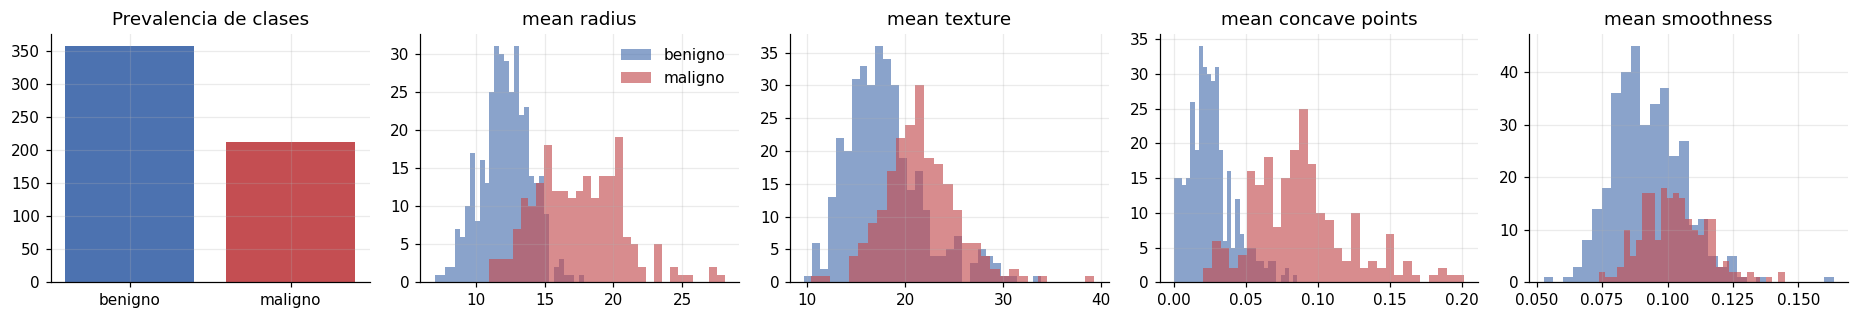

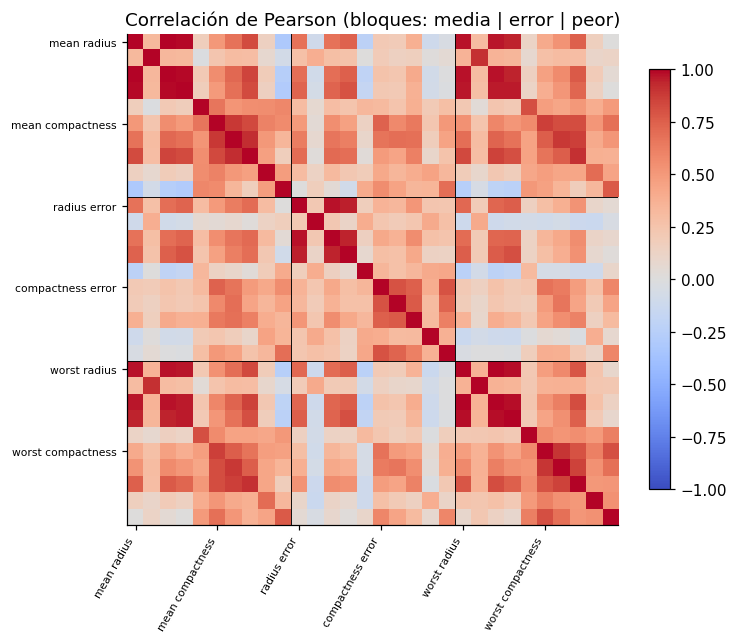

In [ ]:
# CELDA 3 · Perfil de datos (Paso 1)
from sklearn.linear_model import LinearRegression

n_filas = len(df)
nulos_total = int(df[COLUMNAS].isna().sum().sum())
dup_exactos = int(df.duplicated().sum())
conflictos = int((df.groupby(COLUMNAS)[OBJETIVO].nunique() > 1).sum())
negativos = int((df[COLUMNAS] < 0).sum().sum())
prevalencia = float(df[OBJETIVO].mean())

filas = []
for c in COLUMNAS:
    x = df[c].dropna()
    q1, q3 = x.quantile([0.25, 0.75]); iqr = q3 - q1
    n_out = int(((x < q1 - 1.5 * iqr) | (x > q3 + 1.5 * iqr)).sum())
    base = next(b for b, cs in GRUPOS_BASE.items() if c in cs)
    est = "media" if c.startswith("mean ") else ("error" if c.endswith(" error") else "peor")
    filas.append({"Variable": c, "Medida": base, "Estadístico": est, "Nulos %": round(100 * df[c].isna().mean(), 2),
                  "Mín": x.min(), "Máx": x.max(), "Media": x.mean(), "Mediana": x.median(), "Desv.": x.std(),
                  "Asimetría": stats.skew(x), "Atípicos IQR %": round(100 * n_out / len(x), 1)})
perfil = pd.DataFrame(filas).set_index("Variable")

def vif(frame, columnas):
    out = {}
    for c in columnas:
        otras = [k for k in columnas if k != c]
        r2 = LinearRegression().fit(frame[otras], frame[c]).score(frame[otras], frame[c])
        out[c] = np.inf if r2 >= 1 - 1e-12 else 1.0 / (1.0 - r2)
    return pd.Series(out, name="VIF").sort_values(ascending=False)

VIF = vif(df[COLUMNAS].dropna(), COLUMNAS)
CORR = df[COLUMNAS].corr()
pares = [(a, b, CORR.loc[a, b]) for i, a in enumerate(COLUMNAS) for b in COLUMNAS[i + 1:] if abs(CORR.loc[a, b]) > 0.95]
pares = sorted(pares, key=lambda t: -abs(t[2]))

print(f"Casos: {n_filas} | nulos totales: {nulos_total} | duplicados exactos: {dup_exactos} | "
      f"grupos en conflicto (mismas X, distinto diagnóstico): {conflictos} | valores negativos: {negativos}")
print(f"Prevalencia de malignos: {prevalencia:.1%}  (una exactitud trivial 'siempre benigno' sería {1 - prevalencia:.1%})")
display(perfil.round(3).head(12))
print(f"... (30 variables; tabla completa en perfil_datos.csv)")
print(f"\nVIF > 10 en {int((VIF > 10).sum())} de 30 variables. Las 6 más altas:")
display(VIF.head(6).round(1).to_frame())
print(f"Pares con |correlación| > 0,95: {len(pares)}. Los 5 primeros:")
for a, b, r in pares[:5]:
    print(f"  {a:22s} ↔ {b:22s}  r = {r:+.3f}")

# ---- Figura 1: prevalencia y distribución por clase ----
fig, axes = plt.subplots(1, 5, figsize=(17, 3))
cuentas = df[OBJETIVO].value_counts().sort_index()
axes[0].bar(["benigno", "maligno"], [cuentas.get(0, 0), cuentas.get(1, 0)], color=["#4C72B0", "#C44E52"])
axes[0].set_title("Prevalencia de clases")
for ax, c in zip(axes[1:], ["mean radius", "mean texture", "mean concave points", "mean smoothness"]):
    ax.hist(df.loc[df[OBJETIVO] == 0, c], bins=30, alpha=0.65, color="#4C72B0", label="benigno")
    ax.hist(df.loc[df[OBJETIVO] == 1, c], bins=30, alpha=0.65, color="#C44E52", label="maligno")
    ax.set_title(c)
axes[1].legend(frameon=False)
guardar_fig("fig1_prevalencia_distribuciones.png")

# ---- Figura 2: correlaciones ----
fig, ax = plt.subplots(figsize=(7.2, 6.2))
im = ax.imshow(CORR.values, vmin=-1, vmax=1, cmap="coolwarm")
ax.set_xticks(range(0, 30, 5)); ax.set_xticklabels([COLUMNAS[i] for i in range(0, 30, 5)], rotation=60, ha="right", fontsize=7)
ax.set_yticks(range(0, 30, 5)); ax.set_yticklabels([COLUMNAS[i] for i in range(0, 30, 5)], fontsize=7)
for lim in (9.5, 19.5):
    ax.axhline(lim, color="k", lw=0.6); ax.axvline(lim, color="k", lw=0.6)
ax.grid(False); ax.set_title("Correlación de Pearson (bloques: media | error | peor)")
fig.colorbar(im, ax=ax, shrink=0.8)
guardar_fig("fig2_correlaciones.png", ajustar=False)

perfil.to_csv(DIR_SALIDA / "perfil_datos.csv")
MANIFIESTO["perfil"] = {"n_filas": n_filas, "nulos_totales": nulos_total, "duplicados_exactos": dup_exactos,
                        "grupos_en_conflicto": conflictos, "valores_negativos": negativos,
                        "prevalencia_malignos": prevalencia, "n_vif_mayor_10": int((VIF > 10).sum()),
                        "n_pares_corr_mayor_095": len(pares)}
log("perfil_datos", **MANIFIESTO["perfil"])

**Nota de procedencia (para el reporte).** El archivo no incluye identificador de paciente ni marca de tiempo. Por eso: (i) la **independencia entre filas** es un supuesto, no una verificación; (ii) no se puede validar con datos de un centro o una época distintos, de modo que no sabemos cómo se comportaría el modelo ante un cambio de población o de instrumento. Estas limitaciones se **declaran**, no se ocultan.

# Paso 2 · Problema de investigación: objetivo, métrica, umbral y criterios **pre-registrados**

**Objetivo del paso.** Convertir la pregunta en una **declaración formal y verificable**: qué se predice, con qué métricas, **cómo se elegirá el umbral de decisión** y **qué se considerará aceptable**, todo *antes* de ver el resultado en el test.
**Entregable clave.** El **pre-registro**: JSON con huella SHA-256 y fecha.

### 🔎 Celda 4 — Pre-registro de la investigación

**Qué hace.** Declara en un diccionario: pregunta, clase positiva, métricas, **la lista cerrada de modelos que se evaluarán en el test**, la **regla de parsimonia** para elegir entre familias, la **regla del umbral de decisión** y **cuatro criterios de aceptación**:

- **C1 · Sensibilidad** (detectar malignos) ≥ **0,95** en el test.
- **C2 · Especificidad** ≥ **0,90** en el test.
- **C3 · Calibración (Brier)** ≤ **0,05** en el test. (Referencia: un modelo que siempre predice la prevalencia obtiene ≈ 0,23.)
- **C4 · Estabilidad:** el coeficiente de variación del AUC entre los folds externos de la CV anidada es ≤ **2 %**.

Y dos reglas de decisión sellada:
- **Regla de parsimonia (1 error estándar):** se elige la familia **más simple** (orden: logística < SVM-RBF < Random Forest < HistGB) cuyo AUC anidado medio esté a menos de un error estándar del mejor.
- **Regla del umbral:** el umbral es el que **maximiza la especificidad** sujeto a que la sensibilidad *out-of-fold* (en entrenamiento) sea ≥ **0,97**. Se fija **solo con datos de entrenamiento**.

**Por qué.** Los errores no cuestan igual: un falso negativo (un maligno que pasa desapercibido) es peor que un falso positivo, por eso la sensibilidad exige un objetivo explícito y se fija un margen de seguridad (0,97 en entrenamiento para aspirar a 0,95 en prueba). Fijar umbrales y reglas **antes** del resultado impide ajustarlos para que "pasen".

**Qué observar.** El hash impreso. En un trabajo real, **publica ese hash** (repositorio con fecha, OSF, Zenodo) antes de abrir el test. Recuerda que estos valores son una decisión del **experto de dominio** (clínico), no del algoritmo; los que aquí aparecen son propuestas didácticas.

In [ ]:
# CELDA 4 · Pre-registro (Paso 2)
SENS_MIN = 0.95          # C1
ESPEC_MIN = 0.90         # C2
BRIER_MAX = 0.05         # C3
CV_AUC_MAX_PCT = 2.0     # C4
SENS_OBJ_OOF = 0.97      # regla del umbral (solo entrenamiento)
ORDEN_COMPLEJIDAD = ["Regresión logística", "SVM (RBF)", "Random Forest", "HistGB"]

T_PRE_REGISTRO = datetime.now(timezone.utc)
PRE_REGISTRO = {
    "titulo": "Caso 6.2 - Clasificacion citologica maligno/benigno (WDBC)",
    "fecha_utc": T_PRE_REGISTRO.isoformat(timespec="seconds"),
    "pregunta_investigacion": "Discriminar maligno vs benigno con 30 medidas nucleares, con sensibilidad y especificidad aceptables e incertidumbre cuantificada; decidir si la complejidad se justifica.",
    "tipo_problema": "clasificacion binaria supervisada",
    "clase_positiva": "maligno (1)",
    "variables_predictoras": "30 medidas nucleares (media, error estandar, peor valor de 10 medidas base)",
    "metricas": {"primarias": ["sensibilidad", "especificidad"],
                 "umbral_independientes": ["AUC-ROC", "PR-AUC", "Brier"],
                 "secundarias": ["VPP", "VPN", "exactitud balanceada", "F1", "MCC"]},
    "hipotesis": {"H0": "El modelo seleccionado no cumple simultaneamente C1-C4.",
                  "H1": "El modelo seleccionado cumple sensibilidad, especificidad, calibracion y estabilidad."},
    "familias_candidatas": ORDEN_COMPLEJIDAD,
    "regla_de_parsimonia": "Elegir la familia mas simple (en el orden declarado) cuyo AUC anidado medio >= mejor AUC anidado medio - EE del mejor.",
    "regla_del_umbral": {"descripcion": "Maximizar especificidad sujeto a sensibilidad OOF >= objetivo; usando solo entrenamiento",
                         "sens_objetivo_oof": SENS_OBJ_OOF},
    "modelos_a_evaluar_en_test": ["Dummy (prior)"] + ORDEN_COMPLEJIDAD,
    "criterios_de_aceptacion": {
        "C1_sensibilidad": {"regla": "sensibilidad_test >= minimo", "minimo": SENS_MIN},
        "C2_especificidad": {"regla": "especificidad_test >= minimo", "minimo": ESPEC_MIN},
        "C3_calibracion": {"regla": "Brier_test <= maximo", "maximo": BRIER_MAX},
        "C4_estabilidad": {"regla": "CV% del AUC entre folds externos (CV anidada) <= maximo", "cv_max_pct": CV_AUC_MAX_PCT},
    },
    "plan_estadistico": {"intervalos": f"bootstrap percentil 95% (B={N_BOOT}); Clopper-Pearson exacto para sensibilidad y especificidad",
                         "comparacion_de_modelos": "bootstrap pareado sobre filas (no t-test sobre folds)",
                         "validacion": f"CV estratificada repetida {N_REPEATS}x{N_SPLITS} + CV anidada por familia"},
    "protocolo_datos": {"semilla": RANDOM_STATE, "test_size": TEST_SIZE, "particion": "estratificada por clase",
                        "test_sellado": "una sola evaluacion de la lista cerrada de modelos"},
    "huella_datos_sha256": HUELLA_DATOS,
}
PRE_REGISTRO_JSON = json.dumps(PRE_REGISTRO, indent=2, ensure_ascii=False, sort_keys=True, default=a_json)
PRE_REGISTRO_HASH = hashlib.sha256(PRE_REGISTRO_JSON.encode("utf-8")).hexdigest()
(DIR_SALIDA / "pre_registro.json").write_text(PRE_REGISTRO_JSON, encoding="utf-8")

print("PRE-REGISTRO sellado el", PRE_REGISTRO["fecha_utc"], "(UTC)")
print("SHA-256 :", PRE_REGISTRO_HASH)
print(f"Criterios: C1 sens >= {SENS_MIN} | C2 espec >= {ESPEC_MIN} | C3 Brier <= {BRIER_MAX} | C4 CV% AUC <= {CV_AUC_MAX_PCT}")
print(f"Regla del umbral: maximizar especificidad con sensibilidad OOF >= {SENS_OBJ_OOF} | Parsimonia: 1 error estándar")
MANIFIESTO["pre_registro"] = {"sha256": PRE_REGISTRO_HASH, "fecha_utc": PRE_REGISTRO["fecha_utc"]}
log("pre_registro", sha256=PRE_REGISTRO_HASH)

PRE-REGISTRO sellado el 2026-10-19T10:28:29+00:00 (UTC)
SHA-256 : a27b1f09583e65136a97a4734cfd7830f1de4125be4c9bc3194820bc44ebb0c2
Criterios: C1 sens >= 0.95 | C2 espec >= 0.9 | C3 Brier <= 0.05 | C4 CV% AUC <= 2.0
Regla del umbral: maximizar especificidad con sensibilidad OOF >= 0.97 | Parsimonia: 1 error estándar


# Paso 3 · Seleccionar y preparar los datos

**Objetivo del paso.** Dividir los datos **antes de cualquier ajuste**, de modo que ninguna decisión de modelado haya visto el conjunto de prueba, y construir el esquema de validación cruzada.
**Principios.** (1) Partición **estratificada** (se conserva la proporción de malignos). (2) Toda transformación aprendida (imputación, escalado) vive **dentro del pipeline**. (3) El test queda **sellado**.

### 🔎 Celda 5 — Partición estratificada y *test sellado*

**Qué hace.**
1. Reserva ≈20 % de los casos para el test con `StratifiedShuffleSplit` (semilla fija), **conservando la proporción de malignos**, y verifica que no haya casos compartidos.
2. Comprueba que la **prevalencia** sea similar en entrenamiento y prueba.
3. Compara las distribuciones de las 30 variables entre ambos conjuntos como **chequeo de sensatez** (prueba de Kolmogorov-Smirnov y diferencia de medias en desviaciones).
4. Calcula la **huella** de los índices y encierra el test en una **bóveda** (`BovedaTest`) que permite **una sola evaluación** de la lista de modelos pre-registrada y devuelve **probabilidades**, no etiquetas: la decisión (umbral) se aplica después y con una regla ya fijada.
5. Elimina de memoria las tablas completas para que no se use el test por accidente.

**Por qué.** Sin estratificar, un test pequeño puede quedar con muy pocos malignos y volver ruidosas todas las métricas. La bóveda convierte "no toques el test" en un mecanismo con registro; es una barrera de **disciplina**, no de seguridad.

**Qué observar.** Prevalencias casi idénticas. En la tabla KS, con 30 pruebas y α = 0,05 se esperan ≈ 1,5 "alarmas" por azar: **no** es evidencia de mala partición; importa más la columna de diferencia en desviaciones (debería ser pequeña).

In [ ]:
# CELDA 5 · Partición estratificada y test sellado (Paso 3)
from sklearn.model_selection import StratifiedShuffleSplit

X_all = df[COLUMNAS].copy()
y_all = df[OBJETIVO].copy()

sss = StratifiedShuffleSplit(n_splits=1, test_size=TEST_SIZE, random_state=RANDOM_STATE)
idx_tr, idx_te = next(sss.split(X_all, y_all))
assert len(set(idx_tr) & set(idx_te)) == 0, "Casos compartidos entre entrenamiento y prueba."
PARTICION_SIN_INTERSECCION = True

X_train = X_all.iloc[idx_tr].reset_index(drop=True)
y_train = y_all.iloc[idx_tr].reset_index(drop=True)
prev_tr, prev_te = float(y_train.mean()), float(y_all.iloc[idx_te].mean())
DIF_PREVALENCIA = abs(prev_tr - prev_te)

# ---- Chequeo de sensatez (solo distribuciones; no se toma ninguna decisión de modelado) ----
X_te_tmp = X_all.iloc[idx_te]
ks = {c: stats.ks_2samp(X_train[c], X_te_tmp[c]) for c in COLUMNAS}
n_p05 = int(sum(v.pvalue < 0.05 for v in ks.values()))
dif_std = pd.Series({c: (X_te_tmp[c].mean() - X_train[c].mean()) / X_train[c].std() for c in COLUMNAS})
top_dif = dif_std.abs().sort_values(ascending=False).head(5).index
tabla_ks = pd.DataFrame({"KS": [ks[c].statistic for c in top_dif], "p": [ks[c].pvalue for c in top_dif],
                         "dif. en desviaciones": dif_std[top_dif].to_numpy()}, index=top_dif)

# ---- Bóveda del test (devuelve probabilidades de la clase positiva) ----
class BovedaTest:
    """Disciplina de test sellado: permite UNA sola evaluación de una lista cerrada de modelos."""
    def __init__(self, X, y, huella):
        self._X, self._y, self.huella = X.copy(), y.copy(), huella
        self._usos, self.t_primer_uso = 0, None
    @property
    def usos(self):
        return self._usos
    @property
    def n(self):
        return len(self._y)
    def evaluar_modelos(self, modelos):
        if self._usos >= 1:
            raise RuntimeError("La bóveda de test ya fue abierta: un segundo uso contamina el test.")
        self._usos += 1
        self.t_primer_uso = datetime.now(timezone.utc)
        log("boveda_abierta", modelos=list(modelos))
        probs = {}
        for k, m in modelos.items():
            P = m.predict_proba(self._X)
            probs[k] = P[:, list(m.classes_).index(1)]
        return probs, self._y.to_numpy().copy()
    def X_para_analisis_posterior(self):
        if self._usos < 1:
            raise RuntimeError("Primero hay que abrir la bóveda con la evaluación pre-registrada.")
        return self._X.copy()

HUELLA_TEST = hashlib.sha256(np.sort(idx_te).astype(np.int64).tobytes()).hexdigest()
HUELLA_TRAIN = hashlib.sha256(np.sort(idx_tr).astype(np.int64).tobytes()).hexdigest()
BOVEDA = BovedaTest(X_all.iloc[idx_te], y_all.iloc[idx_te], HUELLA_TEST)
N_TRAIN, N_TEST = len(X_train), BOVEDA.n
N_POS_TRAIN, N_POS_TEST = int(y_train.sum()), int(round(prev_te * N_TEST))
del X_all, y_all, idx_te, X_te_tmp                      # el test ya solo es accesible a través de la bóveda

print(f"Entrenamiento: {N_TRAIN} casos ({N_POS_TRAIN} malignos, {prev_tr:.1%}) | Test sellado: {N_TEST} casos ({N_POS_TEST} malignos, {prev_te:.1%})")
print(f"Diferencia de prevalencia: {100 * DIF_PREVALENCIA:.2f} puntos porcentuales")
print(f"Pruebas KS con p < 0,05: {n_p05} de 30 (por azar se esperan ≈ 1,5). Las 5 mayores diferencias:")
display(tabla_ks.round(4))
print("Huella índices train:", HUELLA_TRAIN[:16], "... | test:", HUELLA_TEST[:16], "...")

MANIFIESTO["particion"] = {"n_train": N_TRAIN, "n_test": N_TEST, "prevalencia_train": prev_tr, "prevalencia_test": prev_te,
                           "huella_indices_train": HUELLA_TRAIN, "huella_indices_test": HUELLA_TEST, "semilla": RANDOM_STATE}
log("particion", n_train=N_TRAIN, n_test=N_TEST, huella_test=HUELLA_TEST)

Entrenamiento: 455 casos (170 malignos, 37.4%) | Test sellado: 114 casos (42 malignos, 36.8%)
Diferencia de prevalencia: 0.52 puntos porcentuales
Pruebas KS con p < 0,05: 0 de 30 (por azar se esperan ≈ 1,5). Las 5 mayores diferencias:


,KS,p,dif. en desviaciones
smoothness error,0.1263,0.0982,0.2548
worst texture,0.1269,0.0941,-0.1869
mean texture,0.1018,0.2804,-0.1490
mean smoothness,0.1057,0.2422,0.1281
perimeter error,0.0648,0.8099,-0.1070


Huella índices train: 77d3b8386b0acc05 ... | test: f2d2227d00421e31 ...


### 🔎 Celda 6 — Validación cruzada **estratificada** repetida

**Qué hace.** Define una CV estratificada repetida (3 repeticiones × 5 folds) con `RepeatedStratifiedKFold`, guarda las particiones como lista (para reutilizar exactamente las mismas) y **verifica** que en cada repetición los folds de validación cubren todos los casos sin solaparse. `CV_UNA` es la primera repetición: una partición exacta, necesaria para las predicciones *out-of-fold*.

**Por qué.** La estratificación mantiene la proporción de malignos en cada fold; la repetición reduce la dependencia de una sola partición. Con ≈ 91 casos por fold (≈ 34 malignos), cada fold es ruidoso: por eso se mira siempre la **variabilidad** entre folds.

**Qué observar.** La verificación de cobertura y el rango de prevalencia por fold (debería ser estrecho).

In [ ]:
# CELDA 6 · Validación cruzada estratificada repetida (Paso 3)
from sklearn.model_selection import RepeatedStratifiedKFold, StratifiedKFold

rskf = RepeatedStratifiedKFold(n_splits=N_SPLITS, n_repeats=N_REPEATS, random_state=RANDOM_STATE + 1)
CV_LISTA = list(rskf.split(X_train, y_train))
CV_UNA = CV_LISTA[:N_SPLITS]                     # primera repetición = partición exacta

ok_cv = True
for r in range(N_REPEATS):
    val = np.concatenate([CV_LISTA[r * N_SPLITS + k][1] for k in range(N_SPLITS)])
    ok_cv &= (len(val) == N_TRAIN) and (len(np.unique(val)) == N_TRAIN)
CV_SIN_FUGA = bool(ok_cv)
prev_folds = np.array([y_train.iloc[v].mean() for _, v in CV_UNA])
print("Particiones de CV:", len(CV_LISTA), f"({N_REPEATS} repeticiones x {N_SPLITS} folds)")
print("Cobertura completa y sin solapes en cada repetición:", CV_SIN_FUGA)
print(f"Tamaño medio de fold de validación: {int(np.mean([len(v) for _, v in CV_LISTA]))} casos | "
      f"prevalencia por fold: {prev_folds.min():.1%} – {prev_folds.max():.1%}")
assert CV_SIN_FUGA
log("cv_definida", n_particiones=len(CV_LISTA), sin_fuga=CV_SIN_FUGA)

Particiones de CV: 15 (3 repeticiones x 5 folds)
Cobertura completa y sin solapes en cada repetición: True
Tamaño medio de fold de validación: 91 casos | prevalencia por fold: 37.4% – 37.4%


### 🔎 Celda 7 — ¿Clustering o clasificación? Comprobación empírica (solo entrenamiento)

**Qué hace.** Con los datos de **entrenamiento** estandarizados, proyecta a 2 componentes principales (PCA) y ejecuta **K-means con k = 2 sin usar etiquetas**. Compara los clusters con el diagnóstico real mediante el **índice de Rand ajustado (ARI)**, la **concordancia** (mejor asignación posible de clusters a clases) y la **silueta**. Dibuja el PCA coloreado por diagnóstico real y por cluster.

**Por qué.** En el análisis de tipo de problema se afirmó que el clustering no responde a la pregunta. Aquí se **comprueba**. Es una exploración: lo aprendido aquí **no se reutiliza** en el modelado (el escalado definitivo ocurre dentro de los pipelines).

**Qué observar.** Si la concordancia es alta pero **no perfecta**, el clustering recupera buena parte de la estructura, pero deja una fracción de casos mal asignados que las etiquetas sí permiten distinguir. Un ARI cercano a 1 indicaría coincidencia casi total; un ARI cercano a 0, coincidencia por azar. Y fíjate en la silueta: valores bajos indican que los grupos no están bien separados en el espacio completo.

Varianza explicada por PC1 y PC2: 44.6% y 18.5%
K-means (k = 2, SIN etiquetas) vs. diagnóstico real:  ARI = 0.662 | concordancia = 90.8% | silueta = 0.343
→ ≈ 42 de 455 casos de entrenamiento quedarían en el cluster 'equivocado' si se usara solo clustering.


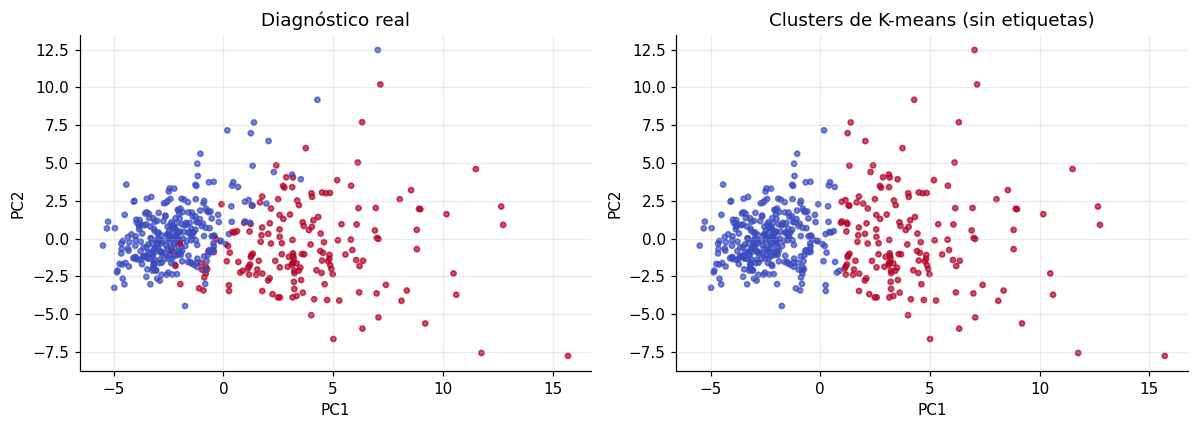

In [ ]:
# CELDA 7 · ¿Clustering o clasificación? (solo entrenamiento; exploración)
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, silhouette_score

Z = StandardScaler().fit_transform(X_train)                       # solo para esta exploración
pca = PCA(n_components=2, random_state=RANDOM_STATE)
P2 = pca.fit_transform(Z)
km = KMeans(n_clusters=2, n_init=10, random_state=RANDOM_STATE).fit(Z)
etiq = km.labels_
yv = y_train.to_numpy()
ARI = float(adjusted_rand_score(yv, etiq))
CONCORDANCIA = float(max(np.mean(etiq == yv), np.mean(etiq != yv)))
SILUETA = float(silhouette_score(Z, etiq))
print(f"Varianza explicada por PC1 y PC2: {pca.explained_variance_ratio_[0]:.1%} y {pca.explained_variance_ratio_[1]:.1%}")
print(f"K-means (k = 2, SIN etiquetas) vs. diagnóstico real:  ARI = {ARI:.3f} | concordancia = {CONCORDANCIA:.1%} | silueta = {SILUETA:.3f}")
print(f"→ ≈ {int(round(N_TRAIN * (1 - CONCORDANCIA)))} de {N_TRAIN} casos de entrenamiento quedarían en el cluster 'equivocado' si se usara solo clustering.")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, colores, titulo in zip(axes, [yv, etiq], ["Diagnóstico real", "Clusters de K-means (sin etiquetas)"]):
    sc = ax.scatter(P2[:, 0], P2[:, 1], c=colores, cmap="coolwarm", s=12, alpha=0.7)
    ax.set_xlabel("PC1"); ax.set_ylabel("PC2"); ax.set_title(titulo)
guardar_fig("fig3_clustering_vs_clasificacion.png")

RESULTADOS["clustering_vs_clasificacion"] = {"ari": ARI, "concordancia": CONCORDANCIA, "silueta": SILUETA}
log("exploracion_estructura", ari=ARI, concordancia=CONCORDANCIA)

# Paso 4 · Elegir arquitectura e hiperparámetros iniciales

**Objetivo del paso.** Elegir las familias de modelos y **justificar cada elección por escrito**. No hay un "mejor modelo" a priori (*no free lunch*): lo que se justifica es el **papel** de cada uno.
**Entregable clave.** Tabla de justificación + espacios de hiperparámetros declarados.

### 🔎 Celda 8 — Modelos, líneas base y espacios de búsqueda

**Qué hace.** Define cinco modelos, como **pipelines** (imputación → escalado → modelo) cuando corresponde:

| Modelo | Papel |
|---|---|
| **Dummy (prior)** | Línea base **trivial**: predice siempre la prevalencia. Define el piso (AUC = 0,5). |
| **Regresión logística** | Línea base **simple e interpretable** y primera en el orden de complejidad. |
| **SVM (RBF)** | Frontera no lineal suave; probabilidades por escalado de Platt. |
| **Random Forest** | Ensamble de árboles, robusto y poco sensible a la escala. |
| **HistGB** | Boosting eficiente; el más flexible y el más complejo. |

También declara el **espacio de hiperparámetros** de cada familia y construye la **tabla de justificación**.

**Por qué.** En este problema, con 30 variables informativas y casi linealmente separables, es plausible que la logística rinda tanto como modelos más complejos. Por eso el orden de complejidad y la **regla de parsimonia** (Celda 4) son parte del diseño: la complejidad debe **ganarse**.

**Qué observar.** La tabla de justificación: cada fila responde *¿por qué este modelo?* y *¿qué riesgo tiene?*.

In [ ]:
# CELDA 8 · Modelos, líneas base y espacios de búsqueda (Paso 4)
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from scipy.stats import loguniform

def _imp():
    return ("imputador", SimpleImputer(strategy="median"))

MODELOS = {
    "Dummy (prior)": DummyClassifier(strategy="prior"),
    "Regresión logística": Pipeline([_imp(), ("escalador", StandardScaler()),
                                     ("modelo", LogisticRegression(max_iter=5000))]),
    "SVM (RBF)": Pipeline([_imp(), ("escalador", StandardScaler()),
                           ("modelo", SVC(kernel="rbf", probability=True, random_state=RANDOM_STATE))]),
    "Random Forest": Pipeline([_imp(), ("modelo", RandomForestClassifier(n_estimators=N_TREES, n_jobs=1,
                                                                          random_state=RANDOM_STATE))]),
    "HistGB": Pipeline([_imp(), ("modelo", HistGradientBoostingClassifier(random_state=RANDOM_STATE))]),
}
LR_BASE = "Regresión logística"

ESPACIOS = {
    "Regresión logística": {"modelo__C": loguniform(1e-3, 1e2)},
    "SVM (RBF)": {"modelo__C": loguniform(1e-1, 1e3), "modelo__gamma": loguniform(1e-4, 1e-1)},
    "Random Forest": {"modelo__max_depth": [None, 4, 8, 12], "modelo__min_samples_leaf": [1, 2, 5],
                      "modelo__max_features": ["sqrt", 0.5]},
    "HistGB": {"modelo__learning_rate": loguniform(0.02, 0.3), "modelo__max_leaf_nodes": [4, 8, 15],
               "modelo__min_samples_leaf": [5, 10, 20], "modelo__l2_regularization": loguniform(1e-3, 10.0),
               "modelo__max_iter": [100, 200, 300]},
}
DESC_ESPACIOS = {"Regresión logística": "C: log-uniforme [1e-3, 1e2]",
                 "SVM (RBF)": "C: log-uniforme [0.1, 1e3] · gamma: log-uniforme [1e-4, 0.1]",
                 "Random Forest": "profundidad {None, 4, 8, 12} · min. hoja {1, 2, 5} · max. variables {sqrt, 0.5}",
                 "HistGB": "tasa de aprendizaje log-uniforme [0.02, 0.3] · hojas {4, 8, 15} · min. hoja {5, 10, 20} · L2 · iteraciones {100, 200, 300}"}

tabla_justificacion = pd.DataFrame([
    ["Dummy (prior)", "Línea base trivial", "Fija el piso: lo que se logra sin aprender (AUC = 0,5)", "Ninguna", "No sirve para decidir"],
    ["Regresión logística", "Línea base simple (1.º en complejidad)", "Interpretable; probabilidades bien calibradas por construcción; rápida", "Colinealidad entre medidas (inestabilidad de coeficientes)", "Frontera lineal"],
    ["SVM (RBF)", "Alternativa no lineal suave (2.º)", "Buena con pocas muestras y muchas variables", "Sensible a escala y a gamma/C", "Probabilidades vía Platt (aproximadas)"],
    ["Random Forest", "Ensamble no lineal (3.º)", "Robusto; capta interacciones; poco sensible a escala", "Probabilidades poco calibradas", "Menos estable con pocos casos"],
    ["HistGB", "Boosting (4.º, el más complejo)", "Alta flexibilidad", "Muchos hiperparámetros", "Sobreajuste con n pequeño"],
], columns=["Modelo", "Rol", "¿Por qué?", "Fortaleza", "Riesgo"]).set_index("Modelo")
display(tabla_justificacion)
tabla_justificacion.to_csv(DIR_SALIDA / "tabla_justificacion.csv")
print("\nEspacios de hiperparámetros declarados:")
for k_, d_ in DESC_ESPACIOS.items():
    print(f"  {k_:20s} {d_}")
log("modelos_definidos", modelos=list(MODELOS), orden=ORDEN_COMPLEJIDAD)

,Rol,¿Por qué?,Fortaleza,Riesgo
Modelo,,,,
Dummy (prior),Línea base trivial,Fija el piso: lo que se logra sin aprender (AU...,Ninguna,No sirve para decidir
Regresión logística,Línea base simple (1.º en complejidad),Interpretable; probabilidades bien calibradas ...,Colinealidad entre medidas (inestabilidad de c...,Frontera lineal
SVM (RBF),Alternativa no lineal suave (2.º),Buena con pocas muestras y muchas variables,Sensible a escala y a gamma/C,Probabilidades vía Platt (aproximadas)
Random Forest,Ensamble no lineal (3.º),Robusto; capta interacciones; poco sensible a ...,Probabilidades poco calibradas,Menos estable con pocos casos
HistGB,"Boosting (4.º, el más complejo)",Alta flexibilidad,Muchos hiperparámetros,Sobreajuste con n pequeño



Espacios de hiperparámetros declarados:
  Regresión logística  C: log-uniforme [1e-3, 1e2]
  SVM (RBF)            C: log-uniforme [0.1, 1e3] · gamma: log-uniforme [1e-4, 0.1]
  Random Forest        profundidad {None, 4, 8, 12} · min. hoja {1, 2, 5} · max. variables {sqrt, 0.5}
  HistGB               tasa de aprendizaje log-uniforme [0.02, 0.3] · hojas {4, 8, 15} · min. hoja {5, 10, 20} · L2 · iteraciones {100, 200, 300}


# Paso 5 · Supervisar el entrenamiento y la validación

**Objetivo del paso.** Estimar el desempeño **sin tocar el test**, comparar familias de forma **honesta** y fijar el **umbral de decisión** y la regla de selección con datos de entrenamiento únicamente.
**Entregables clave.** Tabla de CV, curvas de aprendizaje, CV anidada por familia, modelo seleccionado, umbral, calibración.

### 🔎 Celda 9 — Validación cruzada repetida de los cinco modelos (configuración inicial)

**Qué hace.** Evalúa cada modelo **con sus hiperparámetros por defecto** en la CV estratificada repetida (15 particiones), midiendo AUC, PR-AUC, sensibilidad (con umbral 0,5), exactitud balanceada, Brier y la **brecha** entrenamiento–validación del AUC. Resume con media, desviación y **CV%**, y dibuja el AUC por fold.

**Por qué.** Es una primera comparación **sin ajuste**: muestra qué tan cerca están las familias entre sí y cuánto varía el desempeño entre folds. La brecha entrenamiento–validación revela sobreajuste.

**Qué observar.**
- *Dummy:* AUC = 0,5 y sensibilidad 0: el piso.
- *Diferencias entre familias:* en este dataset suelen ser muy pequeñas; compáralas con la dispersión entre folds (la caja).
- *Exactitud balanceada vs. sensibilidad:* con umbral 0,5 no se garantiza ninguna sensibilidad mínima; por eso el umbral se decide aparte (Celda 12).

  Dummy (prior)        AUC val = 0.5000   (2.7 s)
  Regresión logística  AUC val = 0.9932   (0.8 s)
  SVM (RBF)            AUC val = 0.9934   (1.6 s)
  Random Forest        AUC val = 0.9872   (10.6 s)
  HistGB               AUC val = 0.9920   (6.1 s)


,AUC val,± desv.,CV% AUC,PR-AUC,"Sens (u = 0,5)",Exact. balanceada,Brier,Brecha AUC (train–val)
SVM (RBF),0.9934,0.0053,0.5328,0.9920,0.9451,0.9644,0.0249,0.0042
Regresión logística,0.9932,0.0086,0.8618,0.9926,0.9451,0.9667,0.0217,0.0046
HistGB,0.9920,0.0072,0.7234,0.9899,0.9412,0.9606,0.0286,0.0080
Random Forest,0.9872,0.0094,0.9491,0.9848,0.9216,0.9485,0.0338,0.0128
Dummy (prior),0.5000,0.0000,0.0000,0.3736,0.0000,0.5000,0.2340,0.0000



Mejor familia compleja en esta CV inicial (solo informativo): SVM (RBF)


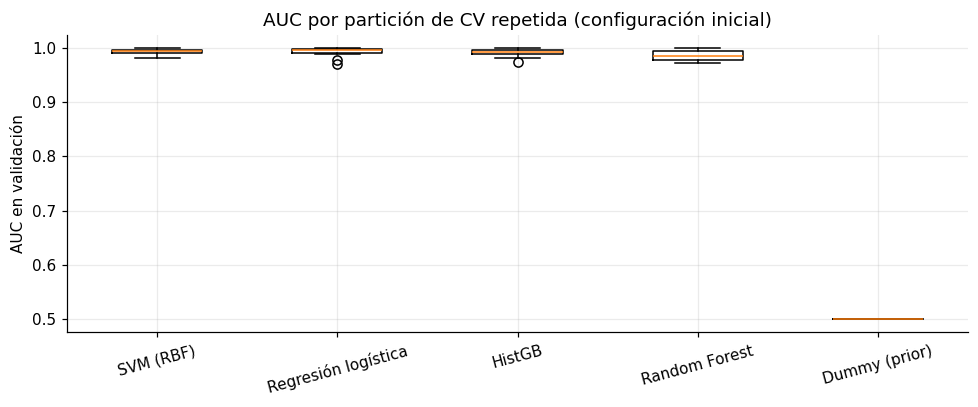

In [ ]:
# CELDA 9 · CV repetida con configuración inicial (Paso 5)
from sklearn.model_selection import cross_validate

scoring = {"auc": "roc_auc", "ap": "average_precision", "bacc": "balanced_accuracy",
           "sens": "recall", "brier": "neg_brier_score"}
RES_CV = {}
for nombre, modelo in MODELOS.items():
    t0 = time.time()
    r = cross_validate(modelo, X_train, y_train, cv=CV_LISTA, scoring=scoring, return_train_score=True, n_jobs=-1)
    RES_CV[nombre] = {"auc": r["test_auc"], "auc_tr": r["train_auc"], "ap": r["test_ap"], "bacc": r["test_bacc"],
                      "sens": r["test_sens"], "brier": -r["test_brier"], "seg": time.time() - t0}
    print(f"  {nombre:20s} AUC val = {RES_CV[nombre]['auc'].mean():.4f}   ({RES_CV[nombre]['seg']:.1f} s)")

tabla_cv = pd.DataFrame({
    k: {"AUC val": v["auc"].mean(), "± desv.": v["auc"].std(ddof=1), "CV% AUC": 100 * v["auc"].std(ddof=1) / v["auc"].mean(),
        "PR-AUC": v["ap"].mean(), "Sens (u = 0,5)": v["sens"].mean(), "Exact. balanceada": v["bacc"].mean(),
        "Brier": v["brier"].mean(), "Brecha AUC (train–val)": (v["auc_tr"] - v["auc"]).mean()}
    for k, v in RES_CV.items()}).T.sort_values("AUC val", ascending=False)
display(tabla_cv.round(4))
tabla_cv.to_csv(DIR_SALIDA / "tabla_cv.csv")

MEJOR_COMPLEJO = max([k for k in ORDEN_COMPLEJIDAD if k != LR_BASE], key=lambda k: RES_CV[k]["auc"].mean())
print(f"\nMejor familia compleja en esta CV inicial (solo informativo): {MEJOR_COMPLEJO}")

orden = list(tabla_cv.index)
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.boxplot([RES_CV[k]["auc"] for k in orden])
ax.set_xticks(range(1, len(orden) + 1)); ax.set_xticklabels(orden, rotation=15)
ax.set_ylabel("AUC en validación"); ax.set_title("AUC por partición de CV repetida (configuración inicial)")
guardar_fig("fig4_cv_auc.png")

RESULTADOS["cv_inicial"] = {k: {"auc_media": float(v["auc"].mean()), "auc_sd": float(v["auc"].std(ddof=1)),
                                "brier_media": float(v["brier"].mean())} for k, v in RES_CV.items()}
log("cv_repetida", mejor_complejo=MEJOR_COMPLEJO)

### 🔎 Celda 10 — Curvas de aprendizaje

**Qué hace.** Para la logística y la mejor familia compleja de la celda anterior, entrena con porciones crecientes del entrenamiento (15 % → 100 %) y grafica la **pérdida logarítmica** (*log loss*) de entrenamiento y de validación (media ± desviación entre folds).

**Por qué.** Responde "¿es suficiente el tamaño de muestra?" **con evidencia empírica**. Se usa log loss y no AUC porque el AUC se satura cerca de 1 y deja de mostrar diferencias, mientras que la log loss sigue reflejando la **calidad de las probabilidades**.

**Qué observar.** Si la curva de validación aún baja al final, más datos mejorarían las probabilidades; una brecha persistente entre curvas indica varianza alta (típica de modelos flexibles con pocos casos); el modelo simple suele tener curvas más juntas.

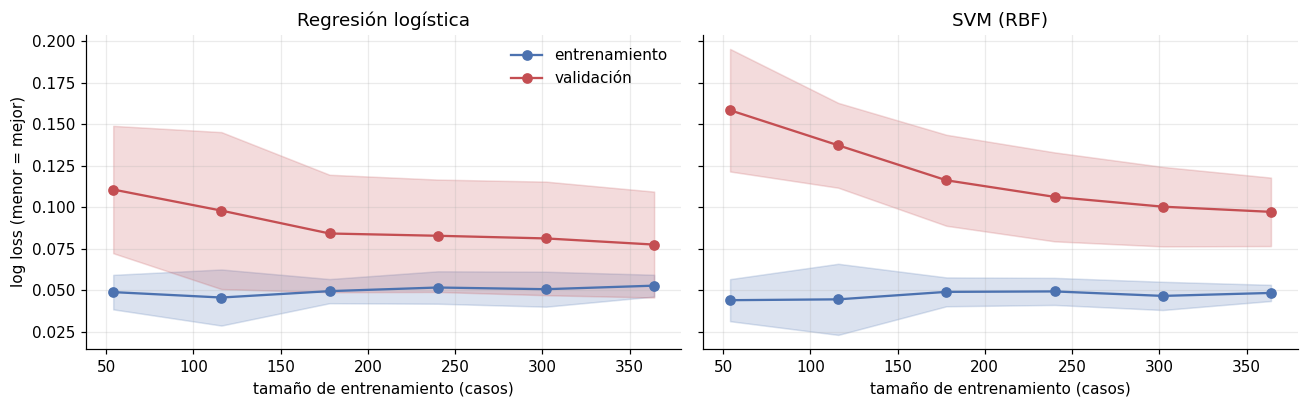

In [ ]:
# CELDA 10 · Curvas de aprendizaje (Paso 5)
from sklearn.model_selection import learning_curve

tamanos = np.linspace(0.15, 1.0, 6)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for ax, nombre in zip(axes, [LR_BASE, MEJOR_COMPLEJO]):
    ts, tr_sc, va_sc = learning_curve(clone(MODELOS[nombre]), X_train, y_train, cv=CV_UNA, train_sizes=tamanos,
                                      scoring="neg_log_loss", n_jobs=-1, shuffle=True, random_state=RANDOM_STATE)
    tr_m, tr_s = (-tr_sc).mean(1), (-tr_sc).std(1)
    va_m, va_s = (-va_sc).mean(1), (-va_sc).std(1)
    ax.plot(ts, tr_m, "o-", color="#4C72B0", label="entrenamiento")
    ax.fill_between(ts, tr_m - tr_s, tr_m + tr_s, color="#4C72B0", alpha=0.2)
    ax.plot(ts, va_m, "o-", color="#C44E52", label="validación")
    ax.fill_between(ts, va_m - va_s, va_m + va_s, color="#C44E52", alpha=0.2)
    ax.set_title(nombre); ax.set_xlabel("tamaño de entrenamiento (casos)")
axes[0].set_ylabel("log loss (menor = mejor)"); axes[0].legend(frameon=False)
guardar_fig("fig5_curvas_aprendizaje.png")
log("curvas_aprendizaje")

### 🔎 Celda 11 — Ajuste de hiperparámetros y **CV anidada por familia** → selección por parsimonia

**Qué hace.** Para **cada familia**:
1. **Búsqueda aleatoria** de hiperparámetros con CV estratificada; el mejor modelo se reajusta con **todo** el entrenamiento y queda listo para el test.
2. **CV anidada:** en cada fold externo se repite *todo el procedimiento* (búsqueda interna con 3 folds + reajuste) usando **solo** el entrenamiento de ese fold. Esto da, para cada familia, un **AUC honesto** por fold externo y **probabilidades *out-of-fold*** de todo el entrenamiento, hechas por modelos que no vieron esos casos.
3. Calcula el **optimismo de selección** (AUC de la búsqueda − AUC anidado).

Después aplica la **regla de parsimonia pre-registrada**: se elige la familia **más simple** cuyo AUC anidado medio esté dentro de **un error estándar** del mejor.

**Por qué.** La mejor puntuación de una búsqueda es optimista por construcción; la CV anidada estima el desempeño del **procedimiento completo**. Y como las diferencias entre familias suelen ser menores que el ruido, la parsimonia evita pagar complejidad por una ventaja que no se distingue del azar. (El error estándar calculado sobre 5 folds es una aproximación habitual, no exacta, porque los folds comparten datos.)

**Qué observar.** El AUC anidado de cada familia con su CV%, el optimismo, y **qué familia se selecciona**. Esta celda es la **más lenta** del cuaderno.

In [ ]:
# CELDA 11 · Búsqueda de hiperparámetros, CV anidada por familia y selección por parsimonia (Paso 5)
from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss

def buscar(modelo, espacio, X, y, cv, n_iter, semilla):
    bs = RandomizedSearchCV(clone(modelo), espacio, n_iter=n_iter, cv=cv, scoring="roc_auc", n_jobs=-1,
                            random_state=semilla, refit=True)
    return bs.fit(X, y)

MODELOS_FINALES, AUC_ANIDADA, OOF_ANIDADO, AUC_BUSQ_OPT, PARAMS_FINALES = {}, {}, {}, {}, {}
y_tr = y_train.to_numpy()
for fam in ORDEN_COMPLEJIDAD:
    t0 = time.time()
    bs = buscar(MODELOS[fam], ESPACIOS[fam], X_train, y_train, CV_UNA, N_ITER_BUSQUEDA, RANDOM_STATE)
    MODELOS_FINALES[fam] = bs.best_estimator_                      # reajustado con TODO el entrenamiento
    AUC_BUSQ_OPT[fam] = float(bs.best_score_)
    PARAMS_FINALES[fam] = {k: (float(v) if isinstance(v, (float, np.floating)) else (int(v) if isinstance(v, (int, np.integer)) else v))
                           for k, v in bs.best_params_.items()}
    aucs, oof = [], np.zeros(len(y_train))
    for k, (tr, va) in enumerate(CV_UNA):
        cv_int = list(StratifiedKFold(3, shuffle=True, random_state=RANDOM_STATE + 100 + k).split(X_train.iloc[tr], y_train.iloc[tr]))
        bk = buscar(MODELOS[fam], ESPACIOS[fam], X_train.iloc[tr], y_train.iloc[tr], cv_int, N_ITER_ANIDADA, RANDOM_STATE + k)
        p = bk.predict_proba(X_train.iloc[va])[:, 1]
        oof[va] = p
        aucs.append(float(roc_auc_score(y_tr[va], p)))
    AUC_ANIDADA[fam] = np.array(aucs)
    OOF_ANIDADO[fam] = oof
    print(f"  {fam:20s} AUC búsqueda = {AUC_BUSQ_OPT[fam]:.4f} | AUC anidado = {AUC_ANIDADA[fam].mean():.4f}   ({time.time() - t0:.0f} s)")

filas = []
for fam in ORDEN_COMPLEJIDAD:
    a = AUC_ANIDADA[fam]
    filas.append({"Familia": fam, "AUC búsqueda (optimista)": AUC_BUSQ_OPT[fam], "AUC anidado (honesto)": a.mean(),
                  "EE": a.std(ddof=1) / np.sqrt(len(a)), "CV% AUC": 100 * a.std(ddof=1) / a.mean(),
                  "Optimismo": AUC_BUSQ_OPT[fam] - a.mean(),
                  "PR-AUC OOF": average_precision_score(y_tr, OOF_ANIDADO[fam]),
                  "Brier OOF": brier_score_loss(y_tr, OOF_ANIDADO[fam])})
tabla_anidada = pd.DataFrame(filas).set_index("Familia")
display(tabla_anidada.round(4))
tabla_anidada.to_csv(DIR_SALIDA / "tabla_cv_anidada.csv")

# ---- Regla de parsimonia pre-registrada (1 error estándar) ----
mejor = max(ORDEN_COMPLEJIDAD, key=lambda f: AUC_ANIDADA[f].mean())
ee_mejor = AUC_ANIDADA[mejor].std(ddof=1) / np.sqrt(len(AUC_ANIDADA[mejor]))
CORTE_PARSIMONIA = AUC_ANIDADA[mejor].mean() - ee_mejor
FAMILIA_SELECCIONADA = next(f for f in ORDEN_COMPLEJIDAD if AUC_ANIDADA[f].mean() >= CORTE_PARSIMONIA)
print(f"\nMejor AUC anidado: {mejor} ({AUC_ANIDADA[mejor].mean():.4f}, EE {ee_mejor:.4f}) → corte de parsimonia = {CORTE_PARSIMONIA:.4f}")
print(f"FAMILIA SELECCIONADA por la regla pre-registrada: {FAMILIA_SELECCIONADA}")
if FAMILIA_SELECCIONADA == LR_BASE:
    print("→ La complejidad adicional NO se justifica: la línea base simple queda dentro de un error estándar del mejor.")

CV_PCT_AUC = float(tabla_anidada.loc[FAMILIA_SELECCIONADA, "CV% AUC"])
T_SELECCION = datetime.now(timezone.utc)
RESULTADOS["anidada"] = {f: {"auc_anidado": float(AUC_ANIDADA[f].mean()), "ee": float(AUC_ANIDADA[f].std(ddof=1) / np.sqrt(len(AUC_ANIDADA[f]))),
                              "cv_pct": float(100 * AUC_ANIDADA[f].std(ddof=1) / AUC_ANIDADA[f].mean()),
                              "auc_busqueda_optimista": AUC_BUSQ_OPT[f], "params": PARAMS_FINALES[f]} for f in ORDEN_COMPLEJIDAD}
RESULTADOS["seleccion"] = {"familia": FAMILIA_SELECCIONADA, "mejor_anidada": mejor, "corte": float(CORTE_PARSIMONIA)}
log("busqueda_y_cv_anidada", seleccionada=FAMILIA_SELECCIONADA)

  Regresión logística  AUC búsqueda = 0.9951 | AUC anidado = 0.9943   (3 s)
  SVM (RBF)            AUC búsqueda = 0.9950 | AUC anidado = 0.9920   (6 s)
  Random Forest        AUC búsqueda = 0.9866 | AUC anidado = 0.9870   (100 s)
  HistGB               AUC búsqueda = 0.9932 | AUC anidado = 0.9894   (41 s)


,AUC búsqueda (optimista),AUC anidado (honesto),EE,CV% AUC,Optimismo,PR-AUC OOF,Brier OOF
Familia,,,,,,,
Regresión logística,0.9951,0.9943,0.0024,0.5318,0.0008,0.9923,0.0254
SVM (RBF),0.9950,0.9920,0.0029,0.6524,0.0031,0.9902,0.0255
Random Forest,0.9866,0.9870,0.0045,1.0135,-0.0004,0.9841,0.0348
HistGB,0.9932,0.9894,0.0041,0.9187,0.0038,0.9842,0.0340



Mejor AUC anidado: Regresión logística (0.9943, EE 0.0024) → corte de parsimonia = 0.9920
FAMILIA SELECCIONADA por la regla pre-registrada: Regresión logística
→ La complejidad adicional NO se justifica: la línea base simple queda dentro de un error estándar del mejor.


### 🔎 Celda 12 — Umbral de decisión, calibración y comparación pareada (solo entrenamiento)

**Qué hace.** Con las **probabilidades *out-of-fold*** de la CV anidada (honestas, nunca vistas por el modelo que las produjo):
1. **Fija el umbral** con la regla pre-registrada: el que **maximiza la especificidad** con sensibilidad ≥ 0,97. Reporta sensibilidad y especificidad *out-of-fold* con ese umbral y con el 0,5 habitual, y las matrices de confusión.
2. Dibuja las curvas **ROC** y **PR**, el **diagrama de fiabilidad** (calibración) y la **distribución de probabilidades por clase**. Calcula el **error de calibración esperado (ECE)**.
3. Compara el modelo seleccionado con la **logística** mediante **bootstrap pareado del AUC**.
4. Muestra el estado **preliminar** de los criterios (solo con entrenamiento).

**Por qué.** El umbral 0,5 trata los errores como si costaran lo mismo. Fijar el umbral **con la regla declarada y sin el test** convierte la decisión clínica en un procedimiento auditable. La calibración responde a si "0,8" significa realmente "8 de cada 10 son malignos".

**Qué observar.** El umbral elegido (puede ser menor que 0,5 si hace falta proteger la sensibilidad), cuántos falsos positivos "cuesta" y el IC de la diferencia de AUC con la línea base (si incluye 0, **no hay evidencia** de que la complejidad ayude).

UMBRAL elegido con la regla pre-registrada (solo entrenamiento): 0.2745
  Con umbral 0.274: sensibilidad OOF = 0.971 | especificidad OOF = 0.954 | VP/FN/VN/FP = (165, 5, 272, 13)
  Con umbral 0,500:  sensibilidad OOF = 0.929 | especificidad OOF = 0.993 | VP/FN/VN/FP = (158, 12, 283, 2)
Calibración OOF del modelo seleccionado: Brier = 0.0254 | ECE = 0.0413


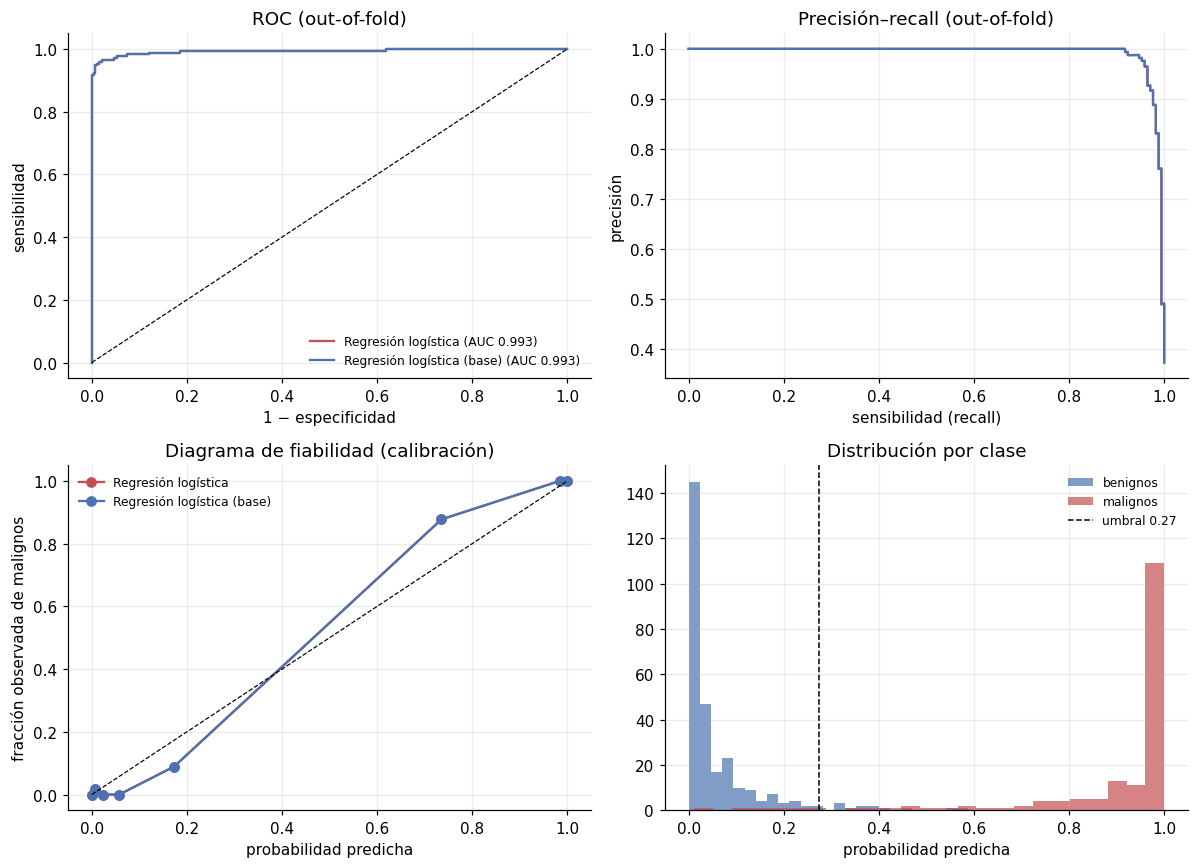


El modelo seleccionado ES la línea base simple: no hay comparación pareada que hacer.

ESTADO PRELIMINAR (solo entrenamiento; el test sigue sellado):


,Umbral pre-registrado,Valor (solo entrenamiento),Estado
Criterio,,,
C4 estabilidad (CV% AUC anidada),≤ 2%,0.53%,✔
Sensibilidad OOF con el umbral elegido (indicio de C1),≥ 0.95,0.971,✔
Especificidad OOF con el umbral elegido (indicio de C2),≥ 0.9,0.954,✔
Brier OOF (indicio de C3),≤ 0.05,0.0254,✔


In [ ]:
# CELDA 12 · Umbral de decisión, calibración y comparación pareada (Paso 5)
from sklearn.metrics import roc_curve, precision_recall_curve, confusion_matrix
from sklearn.calibration import calibration_curve

def elegir_umbral(y, p, sens_obj):
    """Regla pre-registrada: máxima especificidad sujeta a sensibilidad >= sens_obj (solo entrenamiento)."""
    fpr, tpr, thr = roc_curve(y, p)
    ok = np.where((tpr >= sens_obj) & np.isfinite(thr))[0]
    if len(ok) == 0:
        return 0.5, False
    return float(thr[ok[0]]), True                       # primer índice = menor FPR (y mayor umbral)

def ece(y, p, n_bins=10):
    bins = np.linspace(0, 1, n_bins + 1)
    idx = np.clip(np.digitize(p, bins) - 1, 0, n_bins - 1)
    total = 0.0
    for b in range(n_bins):
        m = idx == b
        if m.any():
            total += m.mean() * abs(y[m].mean() - p[m].mean())
    return float(total)

def sens_espec(y, p, u):
    pred = (p >= u).astype(int)
    tp = int(((pred == 1) & (y == 1)).sum()); fn = int(((pred == 0) & (y == 1)).sum())
    tn = int(((pred == 0) & (y == 0)).sum()); fp = int(((pred == 1) & (y == 0)).sum())
    return tp / (tp + fn), tn / (tn + fp), (tp, fn, tn, fp)

p_sel, p_base = OOF_ANIDADO[FAMILIA_SELECCIONADA], OOF_ANIDADO[LR_BASE]
UMBRAL, UMBRAL_ENCONTRADO = elegir_umbral(y_tr, p_sel, SENS_OBJ_OOF)
T_UMBRAL = datetime.now(timezone.utc)
s_u, e_u, cm_u = sens_espec(y_tr, p_sel, UMBRAL)
s_5, e_5, cm_5 = sens_espec(y_tr, p_sel, 0.5)
print(f"UMBRAL elegido con la regla pre-registrada (solo entrenamiento): {UMBRAL:.4f}" + ("" if UMBRAL_ENCONTRADO else "  ⚠️ no se alcanzó la sensibilidad objetivo; se usa 0,5"))
print(f"  Con umbral {UMBRAL:.3f}: sensibilidad OOF = {s_u:.3f} | especificidad OOF = {e_u:.3f} | VP/FN/VN/FP = {cm_u}")
print(f"  Con umbral 0,500:  sensibilidad OOF = {s_5:.3f} | especificidad OOF = {e_5:.3f} | VP/FN/VN/FP = {cm_5}")
print(f"Calibración OOF del modelo seleccionado: Brier = {brier_score_loss(y_tr, p_sel):.4f} | ECE = {ece(y_tr, p_sel):.4f}")

fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for p, nombre, col in [(p_sel, FAMILIA_SELECCIONADA, "#C44E52"), (p_base, LR_BASE + " (base)", "#4C72B0")]:
    fpr, tpr, _ = roc_curve(y_tr, p); axes[0, 0].plot(fpr, tpr, color=col, label=f"{nombre} (AUC {roc_auc_score(y_tr, p):.3f})")
    pr, rc, _ = precision_recall_curve(y_tr, p); axes[0, 1].plot(rc, pr, color=col, label=nombre)
    vt, vp = calibration_curve(y_tr, p, n_bins=8, strategy="quantile"); axes[1, 0].plot(vp, vt, "o-", color=col, label=nombre)
axes[0, 0].plot([0, 1], [0, 1], "k--", lw=0.8); axes[0, 0].set_xlabel("1 − especificidad"); axes[0, 0].set_ylabel("sensibilidad")
axes[0, 0].set_title("ROC (out-of-fold)"); axes[0, 0].legend(frameon=False, fontsize=8)
axes[0, 1].set_xlabel("sensibilidad (recall)"); axes[0, 1].set_ylabel("precisión"); axes[0, 1].set_title("Precisión–recall (out-of-fold)")
axes[1, 0].plot([0, 1], [0, 1], "k--", lw=0.8); axes[1, 0].set_xlabel("probabilidad predicha"); axes[1, 0].set_ylabel("fracción observada de malignos")
axes[1, 0].set_title("Diagrama de fiabilidad (calibración)"); axes[1, 0].legend(frameon=False, fontsize=8)
axes[1, 1].hist(p_sel[y_tr == 0], bins=25, alpha=0.7, color="#4C72B0", label="benignos")
axes[1, 1].hist(p_sel[y_tr == 1], bins=25, alpha=0.7, color="#C44E52", label="malignos")
axes[1, 1].axvline(UMBRAL, color="k", ls="--", lw=1, label=f"umbral {UMBRAL:.2f}")
axes[1, 1].set_xlabel("probabilidad predicha"); axes[1, 1].set_title("Distribución por clase"); axes[1, 1].legend(frameon=False, fontsize=8)
guardar_fig("fig6_oof_roc_pr_calibracion.png")

# ---- Comparación pareada del AUC frente a la línea base (bootstrap sobre filas) ----
def ic95(a):
    lo, hi = np.percentile(a, [2.5, 97.5])
    return float(lo), float(hi)

DIF_AUC_IC, DIF_AUC_MEDIA = None, None
if FAMILIA_SELECCIONADA != LR_BASE:
    rng = np.random.default_rng(RANDOM_STATE + 5)
    difs = []
    for _ in range(N_BOOT):
        i = rng.integers(0, len(y_tr), len(y_tr))
        if y_tr[i].min() == y_tr[i].max():
            continue
        difs.append(roc_auc_score(y_tr[i], p_sel[i]) - roc_auc_score(y_tr[i], p_base[i]))
    difs = np.array(difs); DIF_AUC_MEDIA = float(difs.mean()); DIF_AUC_IC = ic95(difs)
    print(f"\nDiferencia de AUC OOF (seleccionado − logística): {DIF_AUC_MEDIA:+.4f} | IC95% = [{DIF_AUC_IC[0]:+.4f}, {DIF_AUC_IC[1]:+.4f}]")
    print("→ " + ("El IC excluye 0: hay evidencia de diferencia." if DIF_AUC_IC[0] > 0 or DIF_AUC_IC[1] < 0 else "El IC incluye 0: no hay evidencia clara de que la complejidad mejore al modelo simple."))
else:
    print("\nEl modelo seleccionado ES la línea base simple: no hay comparación pareada que hacer.")

prelim = pd.DataFrame([
    ["C4 estabilidad (CV% AUC anidada)", f"≤ {CV_AUC_MAX_PCT:.0f}%", f"{CV_PCT_AUC:.2f}%", "✔" if CV_PCT_AUC <= CV_AUC_MAX_PCT else "✘"],
    ["Sensibilidad OOF con el umbral elegido (indicio de C1)", f"≥ {SENS_MIN}", f"{s_u:.3f}", "✔" if s_u >= SENS_MIN else "✘"],
    ["Especificidad OOF con el umbral elegido (indicio de C2)", f"≥ {ESPEC_MIN}", f"{e_u:.3f}", "✔" if e_u >= ESPEC_MIN else "✘"],
    ["Brier OOF (indicio de C3)", f"≤ {BRIER_MAX}", f"{brier_score_loss(y_tr, p_sel):.4f}", "✔" if brier_score_loss(y_tr, p_sel) <= BRIER_MAX else "✘"],
], columns=["Criterio", "Umbral pre-registrado", "Valor (solo entrenamiento)", "Estado"]).set_index("Criterio")
print("\nESTADO PRELIMINAR (solo entrenamiento; el test sigue sellado):")
display(prelim)
RESULTADOS["preliminar"] = {"umbral": UMBRAL, "sens_oof": s_u, "espec_oof": e_u, "ece_oof": ece(y_tr, p_sel),
                            "dif_auc_media": DIF_AUC_MEDIA, "dif_auc_ic": DIF_AUC_IC}
log("umbral_y_calibracion", umbral=UMBRAL, sens_oof=s_u, espec_oof=e_u)

# Paso 6 · Interpretar los resultados y documentar el artefacto

**Objetivo del paso.** Evaluar **una sola vez** en el test sellado, decidir contra los criterios **pre-registrados**, entender qué usa el modelo, auditar los errores y empaquetar todo de forma auditable.

### 🔎 Celda 13 — Evaluación final en el test sellado (**una sola vez**)

**Qué hace.** (1) Reajusta la línea base trivial. (2) **Abre la bóveda una única vez** para obtener las **probabilidades** de los cinco modelos pre-registrados. (3) Aplica el **umbral fijado en la Celda 12** (no se reajusta). (4) Calcula AUC, PR-AUC y Brier con IC por bootstrap; y, con el umbral, **sensibilidad y especificidad con intervalos exactos de Clopper-Pearson**, VPP, VPN, exactitud balanceada, F1 y MCC. (5) Evalúa los criterios **C1–C4** y añade una columna de **robustez**: ¿el intervalo de confianza también cumple el umbral, o solo el valor puntual?

**Por qué.** Con ≈ 114 casos (≈ 42 malignos), un solo error cambia la sensibilidad en más de 2 puntos. El **intervalo exacto** muestra esa incertidumbre. Y la columna de robustez evita un error frecuente: declarar "cumple" por un punto que el intervalo no respalda.

**Qué observar.**
- La **forest plot** de AUC: ¿se solapan los intervalos de las familias? Si sí, el test **no puede distinguirlas**.
- La tabla de **criterios**: ✔/✘ por cada uno y, aparte, si el IC lo confirma. Un ✘ **no se corrige**: se reporta y se discute.
- Que el veredicto se apoya en el **valor puntual** (así fue pre-registrado), pero la **conclusión** debe leerse con la robustez.
- **El Dummy con el umbral pre-registrado:** como su probabilidad constante (la prevalencia) supera al umbral, clasifica a *todos* como malignos y obtiene **sensibilidad 1,0 con especificidad 0**. Es la mejor demostración de por qué una sensibilidad alta, sola, no significa nada.

Bóveda abierta. Usos: 1 | casos de test: 114 | malignos: 42

Métricas independientes del umbral en el TEST (★ = seleccionado por la regla pre-registrada):


,AUC [IC95%],PR-AUC,Brier
Modelo,,,
Dummy (prior),"0.5000 [0.5000, 0.5000]",0.3684,0.2327
Regresión logística ★,"0.9960 [0.9861, 1.0000]",0.9943,0.0212
SVM (RBF),"0.9964 [0.9868, 1.0000]",0.9949,0.0222
Random Forest,"0.9967 [0.9894, 1.0000]",0.9947,0.0301
HistGB,"0.9914 [0.9692, 1.0000]",0.9909,0.0260



Métricas con el umbral pre-registrado (0.274) — test: 42 malignos y 72 benignos:


,Sensibilidad [IC exacto],Especificidad [IC exacto],VPP,VPN,Exact. bal.,F1,MCC
Modelo,,,,,,,
Regresión logística,"0.976 [0.874, 0.999]","0.986 [0.925, 1.000]",0.976,0.986,0.981,0.976,0.962
Dummy (prior),"1.000 [0.916, 1.000]","0.000 [0.000, 0.050]",0.368,nan,0.500,0.538,nan



VEREDICTO contra los criterios pre-registrados (modelo: Regresión logística):


,Umbral (pre-registrado),Valor [IC95%],Resultado (punto),Robustez (el IC también cumple)
Criterio,,,,
C1 Sensibilidad,≥ 0.95,"0.976 [0.874, 0.999]",✔ cumple,✘
C2 Especificidad,≥ 0.90,"0.986 [0.925, 1.000]",✔ cumple,✔
C3 Calibración (Brier),≤ 0.05,"0.0212 [0.0063, 0.0437]",✔ cumple,✔
C4 Estabilidad (CV% AUC anidada),≤ 2%,0.53%,✔ cumple,✔


Veredicto global (valor puntual): H1 apoyada: se cumplen los 4 criterios
Robustez: al menos un intervalo de confianza NO respalda el criterio: la evidencia es más débil de lo que sugiere el punto


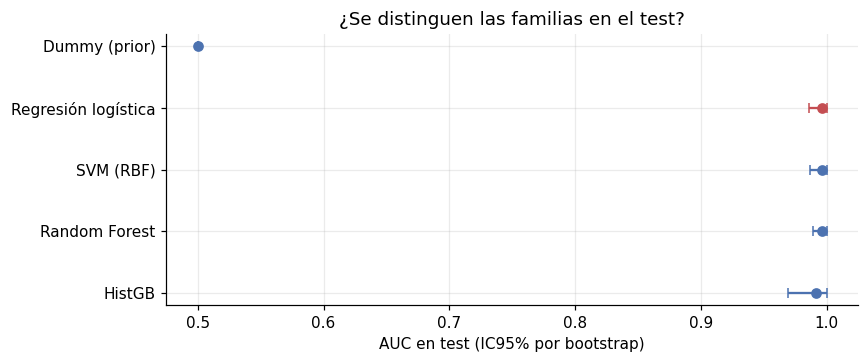

In [ ]:
# CELDA 13 · Evaluación final en el test sellado (Paso 6)
dummy_final = clone(MODELOS["Dummy (prior)"]).fit(X_train, y_train)
MODELOS_TEST = {"Dummy (prior)": dummy_final, **{f: MODELOS_FINALES[f] for f in ORDEN_COMPLEJIDAD}}
K_SEL, K_BASE, K_DUMMY = FAMILIA_SELECCIONADA, LR_BASE, "Dummy (prior)"

PROBS_TEST, Y_TEST = BOVEDA.evaluar_modelos(MODELOS_TEST)          # ← ÚNICO uso de la bóveda
print("Bóveda abierta. Usos:", BOVEDA.usos, "| casos de test:", BOVEDA.n, "| malignos:", int(Y_TEST.sum()))

def ic_exacto(k, n):
    r = stats.binomtest(int(k), int(n)).proportion_ci(confidence_level=0.95, method="exact")
    return float(r.low), float(r.high)

def metricas_clf(y, p, u):
    s, e, (tp, fn, tn, fp) = sens_espec(y, p, u)
    vpp = tp / (tp + fp) if (tp + fp) else float("nan")
    vpn = tn / (tn + fn) if (tn + fn) else float("nan")
    f1 = 2 * tp / (2 * tp + fp + fn)
    den = np.sqrt(float(tp + fp) * (tp + fn) * (tn + fp) * (tn + fn))
    mcc = ((tp * tn) - (fp * fn)) / den if den else float("nan")
    return {"AUC": float(roc_auc_score(y, p)), "AP": float(average_precision_score(y, p)), "Brier": float(brier_score_loss(y, p)),
            "Sens": s, "Espec": e, "VPP": vpp, "VPN": vpn, "BAcc": (s + e) / 2, "F1": f1, "MCC": mcc,
            "Exactitud": (tp + tn) / len(y), "cm": (tp, fn, tn, fp)}

M = {k: metricas_clf(Y_TEST, p, UMBRAL) for k, p in PROBS_TEST.items()}

# ---- Bootstrap (filas) para AUC, PR-AUC, Brier, sensibilidad y especificidad ----
rng = np.random.default_rng(RANDOM_STATE + 7)
BT = {k: {"AUC": [], "AP": [], "Brier": [], "Sens": [], "Espec": []} for k in PROBS_TEST}
DIF_AUC_TEST = []
for _ in range(N_BOOT):
    i = rng.integers(0, len(Y_TEST), len(Y_TEST))
    yb = Y_TEST[i]
    if yb.min() == yb.max():
        continue
    for k, p in PROBS_TEST.items():
        pb = p[i]
        BT[k]["AUC"].append(roc_auc_score(yb, pb)); BT[k]["AP"].append(average_precision_score(yb, pb))
        BT[k]["Brier"].append(brier_score_loss(yb, pb))
        s, e, _ = sens_espec(yb, pb, UMBRAL); BT[k]["Sens"].append(s); BT[k]["Espec"].append(e)
    DIF_AUC_TEST.append(roc_auc_score(yb, PROBS_TEST[K_SEL][i]) - roc_auc_score(yb, PROBS_TEST[K_BASE][i]))
BT = {k: {m: np.array(v) for m, v in d.items()} for k, d in BT.items()}
DIF_AUC_TEST = np.array(DIF_AUC_TEST)

filas = [{"Modelo": k + (" ★" if k == K_SEL else ""), "AUC [IC95%]": f"{M[k]['AUC']:.4f}  [{ic95(BT[k]['AUC'])[0]:.4f}, {ic95(BT[k]['AUC'])[1]:.4f}]",
          "PR-AUC": f"{M[k]['AP']:.4f}", "Brier": f"{M[k]['Brier']:.4f}"} for k in PROBS_TEST]
tabla_auc = pd.DataFrame(filas).set_index("Modelo")
print("\nMétricas independientes del umbral en el TEST (★ = seleccionado por la regla pre-registrada):")
display(tabla_auc)

n_pos, n_neg = int(Y_TEST.sum()), int(len(Y_TEST) - Y_TEST.sum())
filas = []
for k in [K_SEL, K_BASE, K_DUMMY]:
    if k in [f["Modelo"] for f in filas]:
        continue
    tp, fn, tn, fp = M[k]["cm"]
    cs, ce = ic_exacto(tp, tp + fn), ic_exacto(tn, tn + fp)
    filas.append({"Modelo": k, "Sensibilidad [IC exacto]": f"{M[k]['Sens']:.3f}  [{cs[0]:.3f}, {cs[1]:.3f}]",
                  "Especificidad [IC exacto]": f"{M[k]['Espec']:.3f}  [{ce[0]:.3f}, {ce[1]:.3f}]",
                  "VPP": f"{M[k]['VPP']:.3f}", "VPN": f"{M[k]['VPN']:.3f}", "Exact. bal.": f"{M[k]['BAcc']:.3f}",
                  "F1": f"{M[k]['F1']:.3f}", "MCC": f"{M[k]['MCC']:.3f}"})
tabla_umbral = pd.DataFrame(filas).drop_duplicates(subset="Modelo").set_index("Modelo")
print(f"\nMétricas con el umbral pre-registrado ({UMBRAL:.3f}) — test: {n_pos} malignos y {n_neg} benignos:")
display(tabla_umbral)
tabla_auc.to_csv(DIR_SALIDA / "tabla_test_auc.csv"); tabla_umbral.to_csv(DIR_SALIDA / "tabla_test_umbral.csv")

if K_SEL != K_BASE:
    print(f"\nDiferencia de AUC en test (seleccionado − logística): {M[K_SEL]['AUC'] - M[K_BASE]['AUC']:+.4f} | "
          f"IC95% = [{ic95(DIF_AUC_TEST)[0]:+.4f}, {ic95(DIF_AUC_TEST)[1]:+.4f}]")

# ---- Criterios pre-registrados (sobre el modelo seleccionado) ----
tp, fn, tn, fp = M[K_SEL]["cm"]
ic_s, ic_e = ic_exacto(tp, tp + fn), ic_exacto(tn, tn + fp)
ic_brier = ic95(BT[K_SEL]["Brier"])
CRITERIOS = [
    ("C1 Sensibilidad", f"≥ {SENS_MIN:.2f}", f"{M[K_SEL]['Sens']:.3f} [{ic_s[0]:.3f}, {ic_s[1]:.3f}]", bool(M[K_SEL]["Sens"] >= SENS_MIN), bool(ic_s[0] >= SENS_MIN)),
    ("C2 Especificidad", f"≥ {ESPEC_MIN:.2f}", f"{M[K_SEL]['Espec']:.3f} [{ic_e[0]:.3f}, {ic_e[1]:.3f}]", bool(M[K_SEL]["Espec"] >= ESPEC_MIN), bool(ic_e[0] >= ESPEC_MIN)),
    ("C3 Calibración (Brier)", f"≤ {BRIER_MAX:.2f}", f"{M[K_SEL]['Brier']:.4f} [{ic_brier[0]:.4f}, {ic_brier[1]:.4f}]", bool(M[K_SEL]["Brier"] <= BRIER_MAX), bool(ic_brier[1] <= BRIER_MAX)),
    ("C4 Estabilidad (CV% AUC anidada)", f"≤ {CV_AUC_MAX_PCT:.0f}%", f"{CV_PCT_AUC:.2f}%", bool(CV_PCT_AUC <= CV_AUC_MAX_PCT), bool(CV_PCT_AUC <= CV_AUC_MAX_PCT)),
]
tabla_criterios = pd.DataFrame([{"Criterio": a, "Umbral (pre-registrado)": b, "Valor [IC95%]": c,
                                 "Resultado (punto)": "✔ cumple" if d else "✘ no cumple",
                                 "Robustez (el IC también cumple)": "✔" if r else "✘"} for a, b, c, d, r in CRITERIOS]).set_index("Criterio")
print(f"\nVEREDICTO contra los criterios pre-registrados (modelo: {K_SEL}):")
display(tabla_criterios)
VEREDICTO = all(c[3] for c in CRITERIOS)
ROBUSTO = all(c[4] for c in CRITERIOS)
print("Veredicto global (valor puntual):", "H1 apoyada: se cumplen los 4 criterios" if VEREDICTO else
      "H1 NO apoyada en su totalidad: se reporta tal cual (los umbrales no se modifican después)")
print("Robustez:", "los intervalos también respaldan los 4 criterios" if ROBUSTO else
      "al menos un intervalo de confianza NO respalda el criterio: la evidencia es más débil de lo que sugiere el punto")

# ---- Forest plot de AUC ----
nombres = list(PROBS_TEST)
fig, ax = plt.subplots(figsize=(8, 3.4))
for j, k in enumerate(nombres[::-1]):
    lo, hi = ic95(BT[k]["AUC"])
    ax.errorbar(M[k]["AUC"], j, xerr=[[M[k]["AUC"] - lo], [hi - M[k]["AUC"]]], fmt="o", color="#C44E52" if k == K_SEL else "#4C72B0", capsize=3)
ax.set_yticks(range(len(nombres))); ax.set_yticklabels(nombres[::-1]); ax.set_xlabel("AUC en test (IC95% por bootstrap)")
ax.set_title("¿Se distinguen las familias en el test?")
guardar_fig("fig7_forest_auc_test.png")

RESULTADOS["test"] = {"metricas": {k: {m: v for m, v in d.items() if m != "cm"} for k, d in M.items()},
                      "umbral": UMBRAL, "n_test": int(len(Y_TEST)), "n_pos_test": n_pos,
                      "ic_auc": {k: ic95(BT[k]["AUC"]) for k in BT}, "ic_sens_exacto": ic_s, "ic_espec_exacto": ic_e,
                      "criterios": [{"criterio": a, "umbral": b, "valor": c, "cumple": d, "ic_cumple": r} for a, b, c, d, r in CRITERIOS],
                      "veredicto_global": bool(VEREDICTO), "robusto": bool(ROBUSTO)}
log("evaluacion_test", veredicto=bool(VEREDICTO), robusto=bool(ROBUSTO))

### 🔎 Celda 14 — Errores, matrices de confusión, curvas en test y **valores predictivos según la prevalencia**

**Qué hace.**
1. Dibuja las **matrices de confusión** del modelo seleccionado con el umbral pre-registrado y con el 0,5.
2. Grafica la **ROC y la calibración en el test**.
3. Lista los **errores** (falsos negativos y falsos positivos) y los **casos inciertos** (probabilidad entre 0,2 y 0,8), con sus probabilidades y algunas variables clave.
4. Calcula el **VPP y el VPN** que tendría el modelo si la prevalencia fuera la de un **programa de tamizaje**, no la del dataset.

**Por qué.** Los falsos negativos son el error que más importa. Mirar *qué casos* fallan permite que el experto de dominio decida si son casos "difíciles" o señales de un defecto sistemático. El último punto es una advertencia central: **el valor predictivo positivo depende de la prevalencia**. Con la prevalencia de este dataset (≈ 37 %), un resultado positivo es muy informativo; con una prevalencia de tamizaje (≈ 1 %), la misma sensibilidad y especificidad producen **muchos más falsos positivos que verdaderos positivos**.

**Qué observar.** Cuántos FN y FP hay y cómo cambia el umbral entre ambas matrices; la columna de probabilidades de los errores (¿eran casi acertados o muy seguros?); y la tabla de VPP/VPN: el VPP cae drásticamente al bajar la prevalencia.

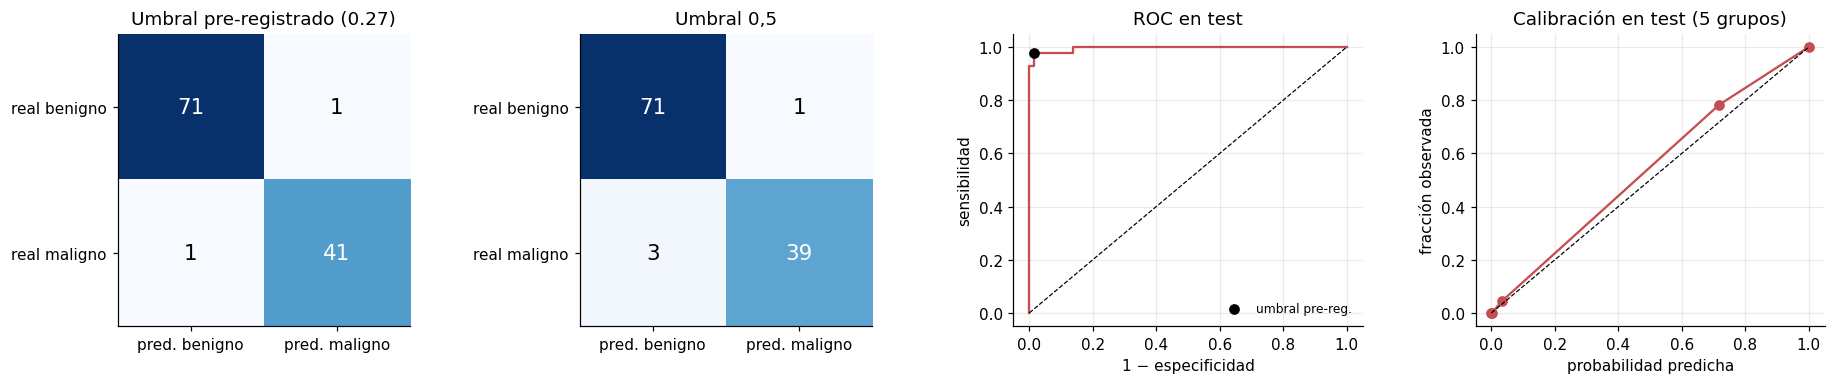

Errores con el umbral pre-registrado: 1 falsos negativos y 1 falsos positivos.


,real,p(maligno),mean radius,mean concave points,worst area,mean texture,tipo
455,benigno,0.509,13.38,0.033,705.6,30.72,falso positivo
73,maligno,0.062,13.80,0.051,812.4,15.79,FALSO NEGATIVO



Casos con probabilidad entre 0,2 y 0,8 (inciertos): 9


,real,p(maligno),mean radius,mean concave points,worst area,mean texture,tipo
99,maligno,0.576,14.42,0.058,826.4,19.77,incierto (acertado)
455,benigno,0.509,13.38,0.033,705.6,30.72,falso positivo
39,maligno,0.761,13.48,0.054,740.4,20.82,incierto (acertado)
208,benigno,0.222,13.11,0.051,639.3,22.54,incierto (acertado)
86,maligno,0.758,14.48,0.049,808.9,21.46,incierto (acertado)
456,benigno,0.237,11.63,0.020,527.8,29.29,incierto (acertado)
190,maligno,0.323,14.22,0.066,762.4,23.12,incierto (acertado)
560,benigno,0.202,14.05,0.043,706.7,27.15,incierto (acertado)
205,maligno,0.491,15.12,0.041,989.5,16.68,incierto (acertado)



Valores predictivos con sensibilidad 0.976 y especificidad 0.986 (las del test) según la prevalencia:


,VPP,VPN,Falsos positivos por cada verdadero positivo
Prevalencia,,,
37.0%,0.976,0.9860,0.02
10.0%,0.886,0.9973,0.13
5.0%,0.787,0.9987,0.27
1.0%,0.415,0.9998,1.41
0.1%,0.066,1.0000,14.21


In [ ]:
# CELDA 14 · Errores, matrices de confusión y valores predictivos según prevalencia (Paso 6)
X_test_post = BOVEDA.X_para_analisis_posterior()
p_t = PROBS_TEST[K_SEL]

fig, axes = plt.subplots(1, 4, figsize=(17, 3.6))
for ax, u, titulo in [(axes[0], UMBRAL, f"Umbral pre-registrado ({UMBRAL:.2f})"), (axes[1], 0.5, "Umbral 0,5")]:
    _, _, (tp_, fn_, tn_, fp_) = sens_espec(Y_TEST, p_t, u)
    cm_ = np.array([[tn_, fp_], [fn_, tp_]])
    ax.imshow(cm_, cmap="Blues"); ax.grid(False)
    for (r_, c_), v in np.ndenumerate(cm_):
        ax.text(c_, r_, str(v), ha="center", va="center", fontsize=14, color="white" if v > cm_.max() / 2 else "black")
    ax.set_xticks([0, 1]); ax.set_xticklabels(["pred. benigno", "pred. maligno"]); ax.set_yticks([0, 1]); ax.set_yticklabels(["real benigno", "real maligno"])
    ax.set_title(titulo)
fpr_t, tpr_t, _ = roc_curve(Y_TEST, p_t)
axes[2].plot(fpr_t, tpr_t, color="#C44E52"); axes[2].plot([0, 1], [0, 1], "k--", lw=0.8)
axes[2].scatter([1 - M[K_SEL]["Espec"]], [M[K_SEL]["Sens"]], color="k", zorder=5, label="umbral pre-reg."); axes[2].legend(frameon=False, fontsize=8)
axes[2].set_xlabel("1 − especificidad"); axes[2].set_ylabel("sensibilidad"); axes[2].set_title("ROC en test")
vt, vp = calibration_curve(Y_TEST, p_t, n_bins=5, strategy="quantile")
axes[3].plot(vp, vt, "o-", color="#C44E52"); axes[3].plot([0, 1], [0, 1], "k--", lw=0.8)
axes[3].set_xlabel("probabilidad predicha"); axes[3].set_ylabel("fracción observada"); axes[3].set_title("Calibración en test (5 grupos)")
guardar_fig("fig8_confusion_roc_calibracion_test.png")

# ---- Errores y casos inciertos ----
pred_u = (p_t >= UMBRAL).astype(int)
clave = ["mean radius", "mean concave points", "worst area", "mean texture"]
tabla_err = X_test_post[clave].copy()
tabla_err.insert(0, "p(maligno)", p_t); tabla_err.insert(0, "real", np.where(Y_TEST == 1, "maligno", "benigno"))
tabla_err["tipo"] = np.select([(Y_TEST == 1) & (pred_u == 0), (Y_TEST == 0) & (pred_u == 1)], ["FALSO NEGATIVO", "falso positivo"], default="")
inciertos = tabla_err[(p_t > 0.2) & (p_t < 0.8)].assign(tipo=lambda d: d["tipo"].where(d["tipo"] != "", "incierto (acertado)"))
errores = tabla_err[tabla_err["tipo"].isin(["FALSO NEGATIVO", "falso positivo"])]
print(f"Errores con el umbral pre-registrado: {int((errores['tipo'] == 'FALSO NEGATIVO').sum())} falsos negativos y {int((errores['tipo'] == 'falso positivo').sum())} falsos positivos.")
display(errores.round(3) if len(errores) else pd.DataFrame({"mensaje": ["Sin errores en el test con este umbral"]}))
print(f"\nCasos con probabilidad entre 0,2 y 0,8 (inciertos): {len(inciertos)}")
if len(inciertos):
    display(inciertos.round(3).head(10))
tabla_err.assign(error=lambda d: d["tipo"] != "").to_csv(DIR_SALIDA / "tabla_errores_test.csv")

# ---- VPP / VPN según prevalencia (teorema de Bayes con la sensibilidad y especificidad del test) ----
s_, e_ = M[K_SEL]["Sens"], M[K_SEL]["Espec"]
filas = []
for prev in [0.37, 0.10, 0.05, 0.01, 0.001]:
    vpp = s_ * prev / (s_ * prev + (1 - e_) * (1 - prev)); vpn = e_ * (1 - prev) / (e_ * (1 - prev) + (1 - s_) * prev)
    filas.append({"Prevalencia": f"{prev:.1%}", "VPP": round(vpp, 3), "VPN": round(vpn, 4),
                  "Falsos positivos por cada verdadero positivo": round((1 - vpp) / vpp, 2) if vpp > 0 else float("inf")})
tabla_prev = pd.DataFrame(filas).set_index("Prevalencia")
print(f"\nValores predictivos con sensibilidad {s_:.3f} y especificidad {e_:.3f} (las del test) según la prevalencia:")
display(tabla_prev)
tabla_prev.to_csv(DIR_SALIDA / "tabla_vpp_prevalencia.csv")

RESULTADOS["errores"] = {"falsos_negativos": int((errores["tipo"] == "FALSO NEGATIVO").sum()),
                         "falsos_positivos": int((errores["tipo"] == "falso positivo").sum()), "inciertos": int(len(inciertos))}
RESULTADOS["vpp_prevalencia"] = tabla_prev.reset_index().to_dict(orient="records")
log("errores_y_prevalencia", **RESULTADOS["errores"])

### 🔎 Celda 15 — Interpretabilidad: **estabilidad de los coeficientes**, permutación por variable y por **grupo de medida**, y SHAP

**Qué hace.**
1. **Estabilidad de la explicación:** reajusta la regresión logística en muchos remuestreos *bootstrap* del entrenamiento y mide, para cada variable (estandarizada), el **intervalo del coeficiente** y **en qué fracción de los remuestreos mantiene el mismo signo**.
2. **Importancia por permutación** (caída del AUC al barajar una variable) en el modelo seleccionado, **por variable** y **por grupo de medida** (radio, perímetro, área, etc.: se barajan juntas las tres versiones: media, error y peor valor).
3. **SHAP** (si se puede instalar) sobre una muestra del test.

**Por qué.** Las variables de este dataset están **muy correlacionadas** (radio, perímetro y área casi coinciden). En ese caso los coeficientes individuales son **inestables** y las importancias por variable se **reparten** entre las redundantes: una explicación basada en una sola corrida puede parecer segura y no serlo. Medir la **estabilidad** es la forma de *auditar* una explicación. Todo esto describe **qué usa el modelo, no qué causa la enfermedad**.

**Qué observar.**
- *Coeficientes:* intervalos que cruzan 0 o con signos que cambian entre remuestreos delatan inestabilidad (típico entre variables redundantes).
- *Permutación:* una variable puede parecer irrelevante individualmente y su **grupo** ser muy importante.
- *SHAP:* compáralo con la permutación; deberían coincidir en lo esencial.

Coeficientes de la logística en 200 remuestreos bootstrap (variables estandarizadas). 10 mayores por |mediana|:


,mediana,p2.5,p97.5,% con signo +,inestable
worst texture,1.377,0.737,1.885,100.0,False
radius error,1.243,0.491,1.792,100.0,False
worst symmetry,1.045,0.579,1.405,100.0,False
mean concave points,0.928,0.455,1.361,100.0,False
worst concavity,0.913,0.617,1.204,100.0,False
area error,0.906,0.598,1.153,100.0,False
compactness error,-0.879,-1.377,-0.338,0.0,False
worst radius,0.875,0.688,1.137,100.0,False
worst area,0.861,0.672,1.101,100.0,False
perimeter error,0.784,0.208,1.233,100.0,False


→ 10 de 30 variables tienen signo inestable (cambia de signo en más del 5 % de los remuestreos).


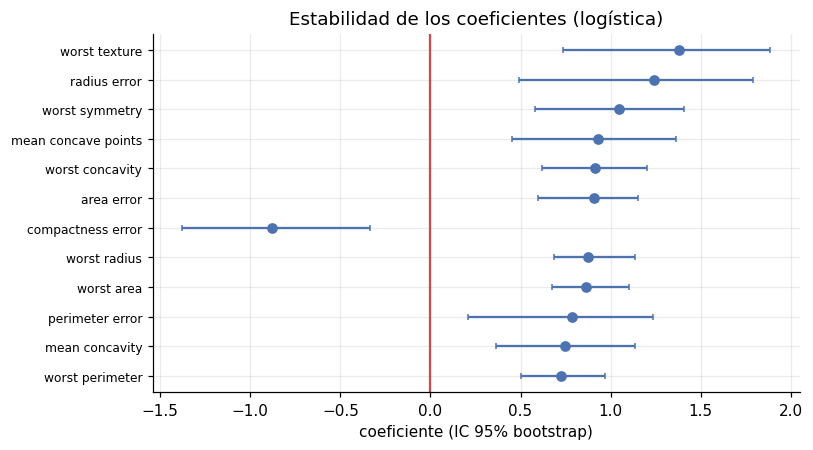


Importancia por permutación en el test (caída de AUC) — modelo Regresión logística:
Mayores 5 variables individuales:


,caída de AUC
worst symmetry,0.0101
worst texture,0.0099
worst concavity,0.0076
worst concave points,0.0029
mean concave points,0.0029


Por GRUPO de medida (se barajan juntas media, error y peor valor):


,caída de AUC
concave points,0.0214
concavity,0.0192
texture,0.0173
radius,0.0149
area,0.0105
perimeter,0.0069
symmetry,0.0057
smoothness,0.0028
compactness,0.0024
fractal dimension,0.0004


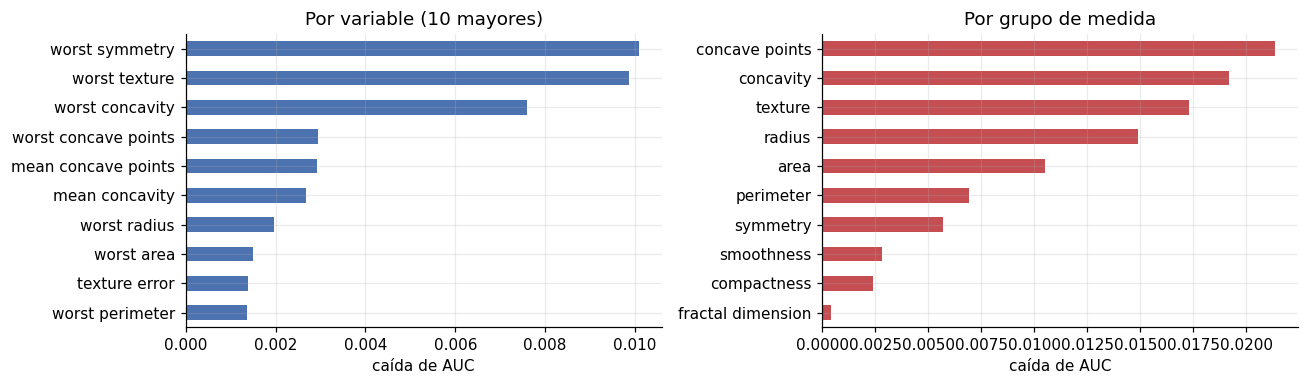

PermutationExplainer explainer: 61it [00:13,  2.94it/s]


SHAP: contribución media absoluta (probabilidad), 8 mayores:


,|SHAP| medio
worst texture,0.0667
worst symmetry,0.0388
mean concave points,0.0375
radius error,0.0366
worst concavity,0.0362
worst radius,0.0357
worst area,0.0320
mean concavity,0.0296


In [ ]:
# CELDA 15 · Interpretabilidad y estabilidad de las explicaciones (Paso 6)
from sklearn.inspection import permutation_importance

# ---- 1) Estabilidad de los coeficientes de la regresión logística (variables estandarizadas) ----
lr_final = MODELOS_FINALES[LR_BASE]
rng = np.random.default_rng(RANDOM_STATE + 3)
coefs = []
for _ in range(B_COEF):
    i = rng.integers(0, len(X_train), len(X_train))
    m = clone(lr_final).fit(X_train.iloc[i], y_train.iloc[i])
    coefs.append(m.named_steps["modelo"].coef_.ravel())
coefs = np.array(coefs)
est = pd.DataFrame({"mediana": np.median(coefs, 0), "p2.5": np.percentile(coefs, 2.5, 0), "p97.5": np.percentile(coefs, 97.5, 0),
                    "% con signo +": 100 * (coefs > 0).mean(0)}, index=COLUMNAS)
est["inestable"] = (est["% con signo +"] > 5) & (est["% con signo +"] < 95)
est["|mediana|"] = est["mediana"].abs()
top = est.sort_values("|mediana|", ascending=False).head(10)
print(f"Coeficientes de la logística en {B_COEF} remuestreos bootstrap (variables estandarizadas). 10 mayores por |mediana|:")
display(top[["mediana", "p2.5", "p97.5", "% con signo +", "inestable"]].round(3))
n_inest = int(est["inestable"].sum())
print(f"→ {n_inest} de 30 variables tienen signo inestable (cambia de signo en más del 5 % de los remuestreos).")

fig, ax = plt.subplots(figsize=(7.5, 4.2))
t12 = est.sort_values("|mediana|", ascending=False).head(12).iloc[::-1]
ax.errorbar(t12["mediana"], range(len(t12)), xerr=[t12["mediana"] - t12["p2.5"], t12["p97.5"] - t12["mediana"]], fmt="o", color="#4C72B0", capsize=2)
ax.axvline(0, color="#C44E52"); ax.set_yticks(range(len(t12))); ax.set_yticklabels(t12.index, fontsize=8)
ax.set_xlabel("coeficiente (IC 95% bootstrap)"); ax.set_title("Estabilidad de los coeficientes (logística)")
guardar_fig("fig9_estabilidad_coeficientes.png")

# ---- 2) Importancia por permutación: por variable y por grupo ----
modelo_sel = MODELOS_FINALES[K_SEL]
y_test_s = pd.Series(Y_TEST)
imp = permutation_importance(modelo_sel, X_test_post, y_test_s, n_repeats=PERM_REPEATS, random_state=RANDOM_STATE,
                             scoring="roc_auc", n_jobs=-1)
imp_var = pd.Series(imp.importances_mean, index=COLUMNAS).sort_values(ascending=False)

def importancia_grupo(modelo, X, y, cols, n_rep, semilla):
    rng_ = np.random.default_rng(semilla)
    base = roc_auc_score(y, modelo.predict_proba(X)[:, 1])
    caidas = []
    for _ in range(n_rep):
        Xp = X.copy(); perm = rng_.permutation(len(X))
        Xp[cols] = X[cols].to_numpy()[perm]
        caidas.append(base - roc_auc_score(y, modelo.predict_proba(Xp)[:, 1]))
    return float(np.mean(caidas))

imp_grupo = pd.Series({b: importancia_grupo(modelo_sel, X_test_post, y_test_s, cols, PERM_REPEATS, RANDOM_STATE) for b, cols in GRUPOS_BASE.items()}).sort_values(ascending=False)
print(f"\nImportancia por permutación en el test (caída de AUC) — modelo {K_SEL}:")
print("Mayores 5 variables individuales:"); display(imp_var.head(5).round(4).to_frame("caída de AUC"))
print("Por GRUPO de medida (se barajan juntas media, error y peor valor):"); display(imp_grupo.round(4).to_frame("caída de AUC"))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
imp_var.head(10).iloc[::-1].plot.barh(ax=axes[0], color="#4C72B0"); axes[0].set_title("Por variable (10 mayores)"); axes[0].set_xlabel("caída de AUC")
imp_grupo.iloc[::-1].plot.barh(ax=axes[1], color="#C44E52"); axes[1].set_title("Por grupo de medida"); axes[1].set_xlabel("caída de AUC")
guardar_fig("fig10_importancia_permutacion.png")

# ---- 3) SHAP (opcional) ----
SHAP_OK = False
try:
    try:
        import shap
    except ImportError:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "shap"], check=False, capture_output=True)
        import shap
    fondo = X_train.sample(min(100, len(X_train)), random_state=RANDOM_STATE)
    muestra = X_test_post.sample(min(60, len(X_test_post)), random_state=RANDOM_STATE)
    explicador = shap.Explainer(lambda Xv: modelo_sel.predict_proba(pd.DataFrame(Xv, columns=COLUMNAS))[:, 1], fondo.to_numpy())
    valores = explicador(muestra.to_numpy())
    shap_medio = pd.Series(np.abs(valores.values).mean(0), index=COLUMNAS).sort_values(ascending=False)
    print("\nSHAP: contribución media absoluta (probabilidad), 8 mayores:")
    display(shap_medio.head(8).round(4).to_frame("|SHAP| medio"))
    SHAP_OK = True
except Exception as e:
    print("\nSHAP no disponible o falló (", type(e).__name__, "). Se continúa sin SHAP.")

RESULTADOS["interpretabilidad"] = {"coef_inestables": n_inest, "permutacion_variable_top": imp_var.head(5).to_dict(),
                                   "permutacion_grupo": imp_grupo.to_dict(), "shap_disponible": SHAP_OK}
log("interpretabilidad", coef_inestables=n_inest, shap=SHAP_OK)

### 🔎 Celda 16 — Documentación: manifiesto, reporte técnico, guion de defensa y paquete

**Qué hace.** Convierte la ejecución en **artefactos auditables**, todos generados desde los resultados reales:
- `manifiesto_ejecucion.json` (versiones, semilla, huellas, hash del pre-registro, uso de la bóveda, resultados y criterios) y `registro_auditoria.json` (bitácora cronológica).
- `requirements.txt` (`pip freeze`) y `modelo_seleccionado.joblib`.
- `reporte_tecnico.md`, `guion_defensa.md`, `traduccion_comite.md` y un `README`.
- Un `.zip` con todo (en Colab se ofrece la descarga).

**Por qué.** Un resultado sin su rastro no es auditable. La tabla de **traducción** conecta la evidencia con las preguntas del comité en su propio lenguaje, y el **guion de defensa** se escribe con los números reales, **incluyendo las limitaciones**.

**Qué observar.** Lee el guion como lo leería un jurado: ¿cada afirmación tiene un número y una referencia en los artefactos? Revisa que la sección de **limitaciones** sea honesta (datos pequeños, sin identificador de paciente, sin variables demográficas, prevalencia no transferible).

In [ ]:
# CELDA 16 · Documentación y artefactos (Paso 6)
import shutil
import joblib

IC_AUC_SEL = ic95(BT[K_SEL]["AUC"])
res_txt = "cumple los cuatro criterios pre-registrados (con el valor puntual)" if VEREDICTO else "no cumple todos los criterios pre-registrados (se reporta tal cual)"
rob_txt = "Los intervalos de confianza respaldan los cuatro criterios." if ROBUSTO else "Atención: al menos un intervalo de confianza no respalda el criterio; la evidencia es más débil de lo que sugiere el valor puntual."
crit_md = "\n".join(f"| {a} | {b} | {c} | {'✔' if d else '✘'} | {'✔' if r else '✘'} |" for a, b, c, d, r in CRITERIOS)
simple_txt = ("La complejidad adicional no se justifica: la regla de parsimonia seleccionó la regresión logística."
              if K_SEL == K_BASE else f"La regla de parsimonia seleccionó {K_SEL}, que supera a la logística dentro de un error estándar; diferencia de AUC en test: {M[K_SEL]['AUC'] - M[K_BASE]['AUC']:+.4f} (IC95% [{ic95(DIF_AUC_TEST)[0]:+.4f}, {ic95(DIF_AUC_TEST)[1]:+.4f}]).")

LIMITACIONES = [
    f"Dataset pequeño: el test tiene {N_TEST} casos ({n_pos} malignos); los intervalos de confianza son anchos y las familias de modelos no se distinguen entre sí en el test.",
    "Sin identificador de paciente: no se pudo verificar la independencia entre filas; si hubiera varias muestras por paciente, el desempeño estaría sobreestimado.",
    "Sin variables demográficas: no se puede auditar sesgo entre subgrupos; el pilar de sesgo queda sin cubrir por limitación de los datos.",
    f"La prevalencia del dataset ({prevalencia:.0%} de malignos) no corresponde a un programa de tamizaje; los valores predictivos no son transferibles (ver tabla de VPP según prevalencia).",
    "Las variables provienen de un proceso de medición (segmentación de imágenes); el modelo hereda su validez y sus errores. No hay validación externa en otro centro o instrumento.",
    "Con variables muy correlacionadas, las importancias y los coeficientes individuales son inestables; describen qué usa el modelo, no causalidad.",
    "Ejercicio metodológico: no es una herramienta diagnóstica.",
]
lim_md = "\n".join(f"- {t}" for t in LIMITACIONES)

reporte = f"""# Reporte técnico · Caso 6.2 (WDBC): clasificación maligno/benigno

## 1. Resumen
Se clasificó la clase *maligno* con 30 medidas nucleares. El modelo seleccionado por la regla de parsimonia pre-registrada fue **{K_SEL}**. En el test sellado ({N_TEST} casos, {n_pos} malignos), con el umbral {UMBRAL:.3f} fijado solo con entrenamiento, obtuvo sensibilidad **{M[K_SEL]['Sens']:.3f}** (IC95% exacto [{ic_s[0]:.3f}, {ic_s[1]:.3f}]), especificidad **{M[K_SEL]['Espec']:.3f}** (IC95% exacto [{ic_e[0]:.3f}, {ic_e[1]:.3f}]) y AUC **{M[K_SEL]['AUC']:.4f}** (IC95% [{IC_AUC_SEL[0]:.4f}, {IC_AUC_SEL[1]:.4f}]). El modelo {res_txt}. {rob_txt} {simple_txt}

## 2. Datos
- Origen: {MANIFIESTO['datos_origen']['fuente']}; Breast Cancer Wisconsin (Diagnostic), UCI (CC BY 4.0). Huella SHA-256 del contenido: `{HUELLA_DATOS}`.
- Casos: {MANIFIESTO['datos_origen']['n_filas']} ({MANIFIESTO['datos_origen']['malignos']} malignos, {MANIFIESTO['datos_origen']['benignos']} benignos). Coincide con la documentación: {MANIFIESTO['datos_origen']['coincide_con_documentacion']}.
- Nulos: {MANIFIESTO['perfil']['nulos_totales']} · duplicados exactos: {MANIFIESTO['perfil']['duplicados_exactos']} · variables con VIF > 10: {MANIFIESTO['perfil']['n_vif_mayor_10']} de 30 · pares con |r| > 0,95: {MANIFIESTO['perfil']['n_pares_corr_mayor_095']}.
- Codificación: **clase positiva = maligno** (scikit-learn codifica 0 = maligno; se recodificó y verificó con los conteos documentados).

## 3. Problema y pre-registro
Clasificación binaria supervisada. Criterios, reglas de parsimonia y del umbral sellados el {PRE_REGISTRO['fecha_utc']} (UTC) con huella `{PRE_REGISTRO_HASH}`.

## 4. Método
- Partición estratificada: entrenamiento {N_TRAIN} casos, test sellado {N_TEST} casos (huella `{HUELLA_TEST[:16]}…`). Semilla {RANDOM_STATE}.
- CV estratificada repetida {N_REPEATS}x{N_SPLITS}; búsqueda aleatoria por familia con **CV anidada**. Transformaciones dentro de pipelines.
- Umbral: máxima especificidad con sensibilidad *out-of-fold* ≥ {SENS_OBJ_OOF}; resultado: **{UMBRAL:.3f}**.

## 5. Resultados en el test
| Modelo | AUC [IC95%] | PR-AUC | Brier |
|---|---|---|---|
""" + "\n".join(f"| {k}{' ★' if k == K_SEL else ''} | {M[k]['AUC']:.4f} [{ic95(BT[k]['AUC'])[0]:.4f}, {ic95(BT[k]['AUC'])[1]:.4f}] | {M[k]['AP']:.4f} | {M[k]['Brier']:.4f} |" for k in PROBS_TEST) + f"""

Con el umbral {UMBRAL:.3f}: VPP {M[K_SEL]['VPP']:.3f}, VPN {M[K_SEL]['VPN']:.3f}, exactitud balanceada {M[K_SEL]['BAcc']:.3f}, MCC {M[K_SEL]['MCC']:.3f}. Errores: {RESULTADOS['errores']['falsos_negativos']} falsos negativos y {RESULTADOS['errores']['falsos_positivos']} falsos positivos.

## 6. Criterios pre-registrados
| Criterio | Umbral | Valor [IC95%] | Resultado | IC también cumple |
|---|---|---|---|---|
{crit_md}

## 7. Incertidumbre, calibración e interpretabilidad
- AUC anidado (honesto) del modelo seleccionado: {AUC_ANIDADA[K_SEL].mean():.4f} (CV% {CV_PCT_AUC:.2f}%); optimismo de selección: {AUC_BUSQ_OPT[K_SEL] - AUC_ANIDADA[K_SEL].mean():+.4f}.
- Calibración OOF: Brier {brier_score_loss(y_tr, p_sel):.4f}, ECE {ece(y_tr, p_sel):.4f}.
- Coeficientes de la logística con signo inestable: {n_inest} de 30. Importancia por grupo de medida: {', '.join(f'{k} ({v:.3f})' for k, v in list(imp_grupo.items())[:3])}.

## 8. Limitaciones
{lim_md}

## 9. Reproducibilidad
Entorno en `requirements.txt` y `manifiesto_ejecucion.json`; semilla {RANDOM_STATE}; ejecutar el cuaderno con *Reiniciar y ejecutar todo*.

## 10. Referencias
Street, W. N., Wolberg, W. H., & Mangasarian, O. L. (1993). Nuclear feature extraction for breast tumor diagnosis. *Proceedings of IS&T/SPIE International Symposium on Electronic Imaging: Science and Technology, 1905*, 861–870.
Wolberg, W., Mangasarian, O., Street, N., & Street, W. (1993). *Breast Cancer Wisconsin (Diagnostic)* [Conjunto de datos]. UCI Machine Learning Repository.
"""

guion = f"""# Guion de defensa · Caso 6.2

*Estimado comité:* este trabajo no se sostiene en mi opinión sobre el modelo, sino en evidencia que pueden auditar.

1. **Los datos.** {MANIFIESTO['datos_origen']['n_filas']} casos del repositorio UCI (WDBC), identificados por su huella y verificados contra los conteos documentados. Nulos: {MANIFIESTO['perfil']['nulos_totales']}; duplicados: {MANIFIESTO['perfil']['duplicados_exactos']}. Declaro que no hay identificador de paciente ni variables demográficas.
2. **El criterio se fijó antes del resultado.** El pre-registro (huella `{PRE_REGISTRO_HASH[:16]}…`) declaró sensibilidad ≥ {SENS_MIN}, especificidad ≥ {ESPEC_MIN}, Brier ≤ {BRIER_MAX}, estabilidad del AUC ≤ {CV_AUC_MAX_PCT}% y **cómo se elegiría el umbral y el modelo**.
3. **El umbral no vio el test.** Se fijó con las predicciones *out-of-fold* para sensibilidad ≥ {SENS_OBJ_OOF}: {UMBRAL:.3f}.
4. **El resultado.** En un test sellado y evaluado una sola vez ({N_TEST} casos, {n_pos} malignos): sensibilidad {M[K_SEL]['Sens']:.3f} [{ic_s[0]:.3f}, {ic_s[1]:.3f}], especificidad {M[K_SEL]['Espec']:.3f} [{ic_e[0]:.3f}, {ic_e[1]:.3f}], AUC {M[K_SEL]['AUC']:.4f}. El modelo {res_txt}. {rob_txt}
5. **¿Complejidad justificada?** {simple_txt}
6. **Lo que NO afirmo.** No afirmo uso clínico, generalización a otras poblaciones o instrumentos, ni equidad entre subgrupos (no hay variables para medirla). Con solo {n_pos} casos malignos en el test, un único error mueve la sensibilidad más de {100 / n_pos:.1f} puntos.
7. **Prevalencia.** Con una prevalencia de tamizaje de 1 %, el VPP sería {float(tabla_prev.loc['1.0%', 'VPP']):.2f}: la mayoría de los positivos serían falsos positivos. Estos valores no son transferibles.
8. **Sobre la validez.** Validez de criterio: sensibilidad, especificidad y AUC en el test sellado. Confiabilidad: estabilidad entre folds y reproducibilidad por semilla y manifiesto. Es una traducción funcional, no una equivalencia.
"""

traduccion = f"""| Lo que pide el comité | Evidencia que entrega este caso |
|---|---|
| ¿Cómo se operacionalizaron las variables? | 30 medidas nucleares documentadas (media, error, peor valor de 10 medidas base); perfil de datos y pipeline declarado. |
| ¿Validez de contenido? | Perfil de calidad del dato y verificación contra conteos documentados (traducción funcional, no equivalencia). |
| ¿Validez de criterio? | Sensibilidad {M[K_SEL]['Sens']:.3f} [{ic_s[0]:.3f}, {ic_s[1]:.3f}] y especificidad {M[K_SEL]['Espec']:.3f} [{ic_e[0]:.3f}, {ic_e[1]:.3f}] en el test sellado. |
| ¿Confiabilidad? | CV% del AUC anidada {CV_PCT_AUC:.2f}% y reproducibilidad exacta por semilla y manifiesto. |
| ¿Tamaño de muestra suficiente? | Curvas de aprendizaje (fig. 5) e intervalos exactos y bootstrap; se declara que el test es pequeño. |
| ¿Se controló el sesgo y la fuga de datos? | Partición estratificada, pipelines, umbral fijado sin el test; el sesgo entre subgrupos no es auditable con estos datos (limitación declarada). |
| ¿Juicio de expertos? | El experto de dominio fija el costo de los errores (sensibilidad objetivo y umbral) en el pre-registro y revisa los casos mal clasificados. |
"""

(DIR_SALIDA / "reporte_tecnico.md").write_text(reporte, encoding="utf-8")
(DIR_SALIDA / "guion_defensa.md").write_text(guion, encoding="utf-8")
(DIR_SALIDA / "traduccion_comite.md").write_text(traduccion, encoding="utf-8")
(DIR_SALIDA / "README.md").write_text(
    "# Caso 6.2 · artefactos\n\nContenido: pre_registro.json, perfil_datos.csv, tablas *.csv, figuras fig*.png, "
    "reporte_tecnico.md, guion_defensa.md, traduccion_comite.md, manifiesto_ejecucion.json, registro_auditoria.json, "
    "requirements.txt, modelo_seleccionado.joblib.\n\nPara reproducir: instalar requirements.txt y ejecutar el cuaderno completo "
    "(el dataset viene incluido en scikit-learn; verificar la huella SHA-256 en el manifiesto).\n"
    "Uso exclusivamente metodológico: no es una herramienta diagnóstica.\n", encoding="utf-8")

joblib.dump(MODELOS_FINALES[K_SEL], DIR_SALIDA / "modelo_seleccionado.joblib")
req = subprocess.run([sys.executable, "-m", "pip", "freeze"], capture_output=True, text=True).stdout
(DIR_SALIDA / "requirements.txt").write_text(req, encoding="utf-8")

MANIFIESTO["fin_utc"] = datetime.now(timezone.utc).isoformat(timespec="seconds")
MANIFIESTO["uso_boveda"] = {"usos": BOVEDA.usos, "primer_uso_utc": BOVEDA.t_primer_uso}
MANIFIESTO["resultados"] = RESULTADOS
MANIFIESTO["tiempos_cv_seg"] = {k: v["seg"] for k, v in RES_CV.items()}
(DIR_SALIDA / "manifiesto_ejecucion.json").write_text(json.dumps(MANIFIESTO, indent=2, ensure_ascii=False, default=a_json), encoding="utf-8")
(DIR_SALIDA / "registro_auditoria.json").write_text(json.dumps(LOG_AUDITORIA, indent=2, ensure_ascii=False, default=a_json), encoding="utf-8")

ruta_zip = shutil.make_archive(str(DIR_SALIDA.parent / "caso62_artefactos"), "zip", DIR_SALIDA)
print("Artefactos guardados en:", DIR_SALIDA.resolve())
print("Paquete comprimido:", ruta_zip)
log("artefactos_generados", zip=ruta_zip)

display(Markdown("### Tabla de traducción para el comité\n\n" + traduccion))
display(Markdown("### Guion de defensa (con los números de esta ejecución)\n\n" + guion))

if EN_COLAB:
    try:
        from google.colab import files
        files.download(ruta_zip)
    except Exception as e:
        print("No se pudo iniciar la descarga automática:", e)

Artefactos guardados en: /content/caso62_salidas
Paquete comprimido: /content/caso62_artefactos.zip


### Tabla de traducción para el comité

| Lo que pide el comité | Evidencia que entrega este caso |
|---|---|
| ¿Cómo se operacionalizaron las variables? | 30 medidas nucleares documentadas (media, error, peor valor de 10 medidas base); perfil de datos y pipeline declarado. |
| ¿Validez de contenido? | Perfil de calidad del dato y verificación contra conteos documentados (traducción funcional, no equivalencia). |
| ¿Validez de criterio? | Sensibilidad 0.976 [0.874, 0.999] y especificidad 0.986 [0.925, 1.000] en el test sellado. |
| ¿Confiabilidad? | CV% del AUC anidada 0.53% y reproducibilidad exacta por semilla y manifiesto. |
| ¿Tamaño de muestra suficiente? | Curvas de aprendizaje (fig. 5) e intervalos exactos y bootstrap; se declara que el test es pequeño. |
| ¿Se controló el sesgo y la fuga de datos? | Partición estratificada, pipelines, umbral fijado sin el test; el sesgo entre subgrupos no es auditable con estos datos (limitación declarada). |
| ¿Juicio de expertos? | El experto de dominio fija el costo de los errores (sensibilidad objetivo y umbral) en el pre-registro y revisa los casos mal clasificados. |


### Guion de defensa (con los números de esta ejecución)

# Guion de defensa · Caso 6.2

*Estimado comité:* este trabajo no se sostiene en mi opinión sobre el modelo, sino en evidencia que pueden auditar.

1. **Los datos.** 569 casos del repositorio UCI (WDBC), identificados por su huella y verificados contra los conteos documentados. Nulos: 0; duplicados: 0. Declaro que no hay identificador de paciente ni variables demográficas.
2. **El criterio se fijó antes del resultado.** El pre-registro (huella `a27b1f09583e6513…`) declaró sensibilidad ≥ 0.95, especificidad ≥ 0.9, Brier ≤ 0.05, estabilidad del AUC ≤ 2.0% y **cómo se elegiría el umbral y el modelo**.
3. **El umbral no vio el test.** Se fijó con las predicciones *out-of-fold* para sensibilidad ≥ 0.97: 0.274.
4. **El resultado.** En un test sellado y evaluado una sola vez (114 casos, 42 malignos): sensibilidad 0.976 [0.874, 0.999], especificidad 0.986 [0.925, 1.000], AUC 0.9960. El modelo cumple los cuatro criterios pre-registrados (con el valor puntual). Atención: al menos un intervalo de confianza no respalda el criterio; la evidencia es más débil de lo que sugiere el valor puntual.
5. **¿Complejidad justificada?** La complejidad adicional no se justifica: la regla de parsimonia seleccionó la regresión logística.
6. **Lo que NO afirmo.** No afirmo uso clínico, generalización a otras poblaciones o instrumentos, ni equidad entre subgrupos (no hay variables para medirla). Con solo 42 casos malignos en el test, un único error mueve la sensibilidad más de 2.4 puntos.
7. **Prevalencia.** Con una prevalencia de tamizaje de 1 %, el VPP sería 0.41: la mayoría de los positivos serían falsos positivos. Estos valores no son transferibles.
8. **Sobre la validez.** Validez de criterio: sensibilidad, especificidad y AUC en el test sellado. Confiabilidad: estabilidad entre folds y reproducibilidad por semilla y manifiesto. Es una traducción funcional, no una equivalencia.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### 🔎 Celda 17 — Lista de verificación de auditoría y prueba de reproducibilidad

**Qué hace.**
1. Verifica de forma **automática** doce condiciones del método (semilla, pre-registro anterior al test, **umbral fijado antes de abrir la bóveda**, partición estratificada sin solapes, bóveda abierta una sola vez, pipelines, CV anidada, intervalos, criterios y artefactos).
2. Ejecuta una **prueba de reproducibilidad**: reajusta el modelo seleccionado desde cero con los mismos hiperparámetros y compara sus probabilidades con las del test.

**Por qué.** Las buenas prácticas que no se comprueban se olvidan. Esta lista es un **mini-auditor** del propio cuaderno.

**Qué observar.** Cada fila con ✔ o ✘; un ✘ es un **hallazgo de auditoría**. En la reproducibilidad, la diferencia máxima debería ser prácticamente cero; si no, documenta la tolerancia y la causa probable.

**Recomendación final.** Haz *Entorno de ejecución → Reiniciar y ejecutar todo* en una sesión limpia y confirma que se obtienen los mismos resultados.

In [ ]:
# CELDA 17 · Lista de verificación de auditoría y prueba de reproducibilidad (Paso 6)
archivos_esperados = ["pre_registro.json", "perfil_datos.csv", "manifiesto_ejecucion.json", "registro_auditoria.json",
                      "reporte_tecnico.md", "guion_defensa.md", "traduccion_comite.md", "requirements.txt", "modelo_seleccionado.joblib"]
pipelines_ok = all(isinstance(m, Pipeline) for k, m in MODELOS.items() if k != "Dummy (prior)")
checks = [
    ("1. Semilla global fijada y registrada", RANDOM_STATE is not None),
    ("2. Huella SHA-256 del contenido de datos registrada", bool(HUELLA_DATOS)),
    ("3. Perfil de datos generado (nulos, duplicados, prevalencia, VIF)", (DIR_SALIDA / "perfil_datos.csv").exists()),
    ("4. Pre-registro creado ANTES de abrir el test sellado", bool(T_PRE_REGISTRO < BOVEDA.t_primer_uso)),
    ("5. Umbral de decisión fijado ANTES de abrir el test sellado", bool(T_UMBRAL < BOVEDA.t_primer_uso)),
    ("6. Partición estratificada sin solapes y con prevalencia similar", bool(PARTICION_SIN_INTERSECCION and DIF_PREVALENCIA < 0.02)),
    ("7. CV sin fuga y transformaciones dentro de pipelines", bool(CV_SIN_FUGA and pipelines_ok)),
    ("8. Línea base trivial y simple evaluadas junto al seleccionado", all(k in PROBS_TEST for k in (K_BASE, K_DUMMY, K_SEL))),
    ("9. Bóveda del test abierta exactamente una vez", BOVEDA.usos == 1),
    ("10. CV anidada realizada para todas las familias", all(len(AUC_ANIDADA[f]) == N_SPLITS for f in ORDEN_COMPLEJIDAD)),
    ("11. Intervalos (bootstrap y exactos) reportados", all(len(BT[k]["AUC"]) > 0.9 * N_BOOT for k in BT)),
    ("12. Criterios pre-registrados evaluados y artefactos completos", len(CRITERIOS) == 4 and all((DIR_SALIDA / a).exists() for a in archivos_esperados)),
]
tabla_checks = pd.DataFrame([{"Verificación": a, "Estado": "✔" if b else "✘"} for a, b in checks]).set_index("Verificación")
display(tabla_checks)
n_ok = sum(b for _, b in checks)
print(f"Resultado: {n_ok}/{len(checks)} verificaciones superadas.")

modelo_repro = clone(MODELOS_FINALES[K_SEL]).fit(X_train, y_train)
p_repro = modelo_repro.predict_proba(BOVEDA.X_para_analisis_posterior())[:, 1]
dif_max = float(np.max(np.abs(p_repro - PROBS_TEST[K_SEL])))
REPRODUCIBLE = dif_max < 1e-6
print(f"\nReproducibilidad: diferencia máxima entre probabilidades = {dif_max:.3e} ->",
      "✔ idénticas dentro de la tolerancia (1e-6)" if REPRODUCIBLE else
      "✘ no idénticas bit a bit: documenta la tolerancia y la causa probable (hilos, versión de librería)")
RESULTADOS["auditoria"] = {"verificaciones_ok": int(n_ok), "total": len(checks), "reproducibilidad_dif_max": dif_max}
log("auditoria_final", ok=int(n_ok), reproducible=bool(REPRODUCIBLE))
(DIR_SALIDA / "registro_auditoria.json").write_text(json.dumps(LOG_AUDITORIA, indent=2, ensure_ascii=False, default=a_json), encoding="utf-8")

,Estado
Verificación,
1. Semilla global fijada y registrada,✔
2. Huella SHA-256 del contenido de datos registrada,✔
"3. Perfil de datos generado (nulos, duplicados, prevalencia, VIF)",✔
4. Pre-registro creado ANTES de abrir el test sellado,✔
5. Umbral de decisión fijado ANTES de abrir el test sellado,✔
6. Partición estratificada sin solapes y con prevalencia similar,✔
7. CV sin fuga y transformaciones dentro de pipelines,✔
8. Línea base trivial y simple evaluadas junto al seleccionado,✔
9. Bóveda del test abierta exactamente una vez,✔


Resultado: 12/12 verificaciones superadas.

Reproducibilidad: diferencia máxima entre probabilidades = 0.000e+00 -> ✔ idénticas dentro de la tolerancia (1e-6)


3096

# Apéndice A · Trampa deliberada: fuga por **selección de variables** antes de la validación (opcional)

### 🔎 Celda 18 — ¿Cuánto "aprende" un procedimiento con fuga cuando **no hay nada que aprender**?

**Qué hace.** Construye un problema **sin señal alguna**: toma 100 casos de entrenamiento, **baraja sus etiquetas** (así, ninguna variable puede predecirlas) y les asocia 1.000 variables de **puro ruido**. Luego compara dos procedimientos con la misma validación cruzada de 5 folds:
- **Con fuga (incorrecto):** elige las 20 "mejores" variables mirando **todas** las etiquetas y *después* valida.
- **Correcto:** hace la selección **dentro** de cada fold (como parte del pipeline).

Se repite varias veces. Como no hay señal, el AUC verdadero es **0,5**.

**Por qué.** Es el error clásico de la selección de variables fuera de la validación: las variables "ganadoras" se eligieron por casualidad **usando justo las etiquetas que luego se pretende predecir**. La validación posterior ya no es independiente y el procedimiento parece haber "descubierto" algo que no existe. Es la razón por la que **todo paso que aprenda de las etiquetas debe vivir dentro del pipeline**.

**Qué observar.** El AUC con fuga muy por encima de 0,5 (¡sin señal alguna!) y el correcto alrededor de 0,5. Esa diferencia es **inflación pura**. Fíjate en que un reporte con fuga *parecería* excelente y un revisor que no mire el código no lo notaría.

**No toca el test real.** Usa solo datos de entrenamiento y etiquetas barajadas.

Repeticiones: 20 | casos: 100 | variables de ruido: 1000 (se eligen 20) | AUC verdadero = 0,5 | 2 s
AUC CON FUGA (selección fuera de la validación): 0.911  ← parece un modelo excelente, y no hay nada que aprender
AUC CORRECTO (selección dentro de cada fold):    0.506  ← ≈ 0,5, como debe ser
Inflación por la fuga: +0.405 de AUC


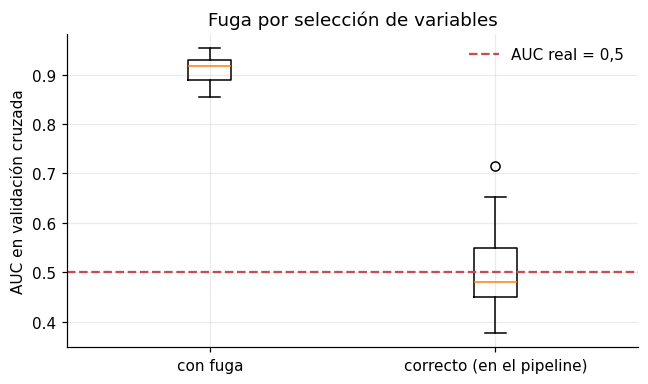

In [ ]:
# CELDA 18 · Trampa deliberada: fuga por selección de variables (opcional; no toca el test real)
if EJECUTAR_TRAMPA:
    from sklearn.feature_selection import SelectKBest, f_classif
    from sklearn.model_selection import cross_val_score
    N_TRAMPA, P_RUIDO, K_VARS = 100, 1000, 20
    rng = np.random.default_rng(RANDOM_STATE + 99)
    t0 = time.time()
    con_fuga, correcto = [], []
    for r in range(TRAMPA_R):
        filas_ = rng.choice(len(y_tr), N_TRAMPA, replace=False)
        y_perm = rng.permutation(y_tr[filas_])                         # etiquetas barajadas: SIN señal
        Xn = rng.standard_normal((N_TRAMPA, P_RUIDO))                  # variables de puro ruido
        cv = StratifiedKFold(5, shuffle=True, random_state=r)
        Xsel = SelectKBest(f_classif, k=K_VARS).fit_transform(Xn, y_perm)          # ← fuga: ve TODAS las etiquetas
        con_fuga.append(cross_val_score(LogisticRegression(max_iter=2000), Xsel, y_perm, cv=cv, scoring="roc_auc").mean())
        pipe = Pipeline([("sel", SelectKBest(f_classif, k=K_VARS)), ("lr", LogisticRegression(max_iter=2000))])
        correcto.append(cross_val_score(pipe, Xn, y_perm, cv=cv, scoring="roc_auc").mean())          # selección DENTRO de cada fold
    con_fuga, correcto = np.array(con_fuga), np.array(correcto)
    print(f"Repeticiones: {TRAMPA_R} | casos: {N_TRAMPA} | variables de ruido: {P_RUIDO} (se eligen {K_VARS}) | AUC verdadero = 0,5 | {time.time() - t0:.0f} s")
    print(f"AUC CON FUGA (selección fuera de la validación): {con_fuga.mean():.3f}  ← parece un modelo excelente, y no hay nada que aprender")
    print(f"AUC CORRECTO (selección dentro de cada fold):    {correcto.mean():.3f}  ← ≈ 0,5, como debe ser")
    print(f"Inflación por la fuga: {con_fuga.mean() - correcto.mean():+.3f} de AUC")
    fig, ax = plt.subplots(figsize=(6, 3.6))
    ax.boxplot([con_fuga, correcto]); ax.axhline(0.5, color="#C44E52", ls="--", label="AUC real = 0,5")
    ax.set_xticks([1, 2]); ax.set_xticklabels(["con fuga", "correcto (en el pipeline)"]); ax.set_ylabel("AUC en validación cruzada")
    ax.set_title("Fuga por selección de variables"); ax.legend(frameon=False)
    guardar_fig("fig11_fuga_seleccion.png")
    RESULTADOS["trampa"] = {"auc_con_fuga": float(con_fuga.mean()), "auc_correcto": float(correcto.mean()), "r": TRAMPA_R}
    log("trampa_fuga_seleccion", auc_con_fuga=float(con_fuga.mean()), auc_correcto=float(correcto.mean()))
else:
    print("Celda 18 omitida (EJECUTAR_TRAMPA = False).")

---
# Cierre del caso: qué se entrega y qué sigue

## Lo que este caso demostró (en el lenguaje del libro)

| Paso | Evidencia producida |
|---|---|
| 1 · Dataset | Huella del contenido, verificación contra conteos documentados, perfil de calidad, colinealidad, codificación explícita (1 = maligno) |
| 2 · Objetivo | Pre-registro sellado: criterios, **regla del umbral** y **regla de parsimonia** antes del test |
| 3 · Preparación | Partición estratificada, pipelines, test sellado con huella, chequeo clustering vs. clasificación |
| 4 · Arquitectura | Tabla de justificación; orden de complejidad; líneas base |
| 5 · Validación | CV repetida, curvas de aprendizaje, **CV anidada por familia**, umbral y calibración sin el test |
| 6 · Resultado | Test evaluado una vez con IC exactos y bootstrap, criterios con **robustez**, errores, VPP por prevalencia, estabilidad de las explicaciones, paquete auditable |

## Ejercicios para el lector

1. **Replica.** Cambia `RANDOM_STATE` (7, 123, 2024) y reporta cómo varían la sensibilidad y la especificidad del test. Con ≈ 42 casos malignos, ¿cuánto confiarías en un solo número?
2. **Rompe (1).** Aplica el escalado a *todos* los datos antes de partir. ¿Cuánto cambia la métrica? Después usa la trampa de la Celda 18: ¿por qué el efecto aquí es enorme y allí casi nulo?
3. **Rompe (2).** Pon el umbral en 0,5 en lugar del pre-registrado. ¿Qué pasa con la sensibilidad en el test y con los falsos negativos? ¿Qué diría el clínico?
4. **Contamina.** Intenta abrir la bóveda por segunda vez. Lee el error y el registro de auditoría.
5. **Cambia la regla.** Elimina la regla de parsimonia y elige directamente la familia con mejor AUC anidado. ¿Cambia el modelo seleccionado? ¿Cambian las conclusiones del test?
6. **Prevalencia.** Calcula el VPP del modelo para la prevalencia de un tamizaje real de tu país. ¿Qué implicaría ese número para un programa de cribado?
7. **Equidad.** Este dataset no tiene variables demográficas. Elige un dataset que sí las tenga y diseña cómo medirías la diferencia de sensibilidad entre subgrupos (por ejemplo, con `fairlearn`).
8. **Defiende.** Reescribe el guion para un comité de ciencias de la salud: ¿qué evidencia de este caso responde a cada una de sus preguntas, y qué reconocerías que **no** puedes afirmar?

## Referencias del dataset

Street, W. N., Wolberg, W. H., & Mangasarian, O. L. (1993). Nuclear feature extraction for breast tumor diagnosis. *Proceedings of IS&T/SPIE International Symposium on Electronic Imaging: Science and Technology, 1905*, 861–870.
Wolberg, W., Mangasarian, O., Street, N., & Street, W. (1993). *Breast Cancer Wisconsin (Diagnostic)* [Conjunto de datos]. UCI Machine Learning Repository (CC BY 4.0).

##**Roiman Valbuena: Metodología de Investigación Algocrática (2027)**